# Repeat Purchase Prediction, part 2
# Data Preprocessing

## Notebook purpose

This notebook turns the raw tables into data a model can use. It follows `01_eda.ipynb`, which found what is wrong with the data and what can be used at prediction time. Here we decide what to do about each finding, test the decisions that are not obvious, and save the result.

The target is `repeat_purchase_90d`: whether a customer buys again within 90 days of a purchase. The competition scores F1, so choices such as the validation design and the threshold are made with F1 in mind rather than accuracy.

This notebook covers:

- Merging the customer table and fixing the problems found in the EDA: placeholder values standing in for missing information, wrong signs, calculation inconsistencies and empty rows;
- Building a validation scheme that respects time order;
- Comparing the main treatment options (missing values, outliers, transformations, scaling, encoding) with the same models and the same folds;
- Feature engineering and feature selection;
- Saving the cleaned data, a decision log and the preprocessing steps in a form that can be reused on the test set.

## Analysis principles

A few rules apply to the whole notebook, and most of them come from the EDA (section 13).

- **Two kinds of steps:**
    - *Stateless* steps work row by row and need nothing learned from the data: fixing a placeholder, recomputing a mean from its own total and count, building a ratio.
    - *Stateful* steps learn something from the data (fill values, encoding maps, scaling, feature selection) and are fitted only on the training part of each fold.
- **Time order.** The predictors describe the customer's history up to the purchase, and the target describes the next 90 days. Validation therefore uses later periods than training, with a 90-day gap so that training outcome windows end before validation begins. This reflects the task of predicting future purchases. A random split could give an overly optimistic estimate of performance.
- **No information from later rows.** A feature may not use any later purchase of the same customer, in train or in test.
- **Decisions are tested, not assumed.** Reasonable preprocessing options are compared using the same models and validation folds. Customer-level bootstrap intervals help assess whether differences in F1 are convincing. When no clear improvement is detected, we prefer the simpler option. These comparisons guide development; the selected approach is assessed later on the reserved holdout.
- **Everything that changes data is logged.** Each decision records the column, the action, the reason and the number of rows affected.
- **Test data is never used to fit anything.**

## Planned structure

1. **Setup and data loading:** paths, packages and constants; loading `train`, `test` and the customer table
2. **Stateless cleaning:**
   - 2.1. Merge the customer table and check dates
   - 2.2. Remove rows without a date
   - 2.3. Replace placeholders with missing values
   - 2.4. Repair inconsistent columns
   - 2.5. Sanity checks on the test set
3. **Validation design:**
   - 3.1. Expanding yearly folds
   - 3.2. How options are compared and how the threshold is chosen
4. **Reference models:**
   - 4.1. Scoring on the folds
5. **Treatment comparisons:**
   - 5.1. Invalid values
   - 5.2. Missing values
   - 5.3. Outliers
   - 5.4. Transformations and scaling
   - 5.5. Encoding the large categorical columns
   - 5.6. Customer-table fields
   - 5.7. Summary of treatment decisions
6. **Feature engineering:**
   - 6.1. Ratio and marker features
   - 6.2. Calendar features
   - 6.3. The customer's past repeat rate
7. **Feature selection and dimensionality reduction:**
   - 7.1. Domain knowledge
   - 7.2. Noise probe
   - 7.3. Filter methods
   - 7.4. Wrapper and embedded methods
   - 7.5. Reduction and vote
   - 7.6. Chaining a second selector before elastic net
   - 7.7. Stability of elastic net
8. **Final preprocessing and outputs:**
   - 8.1. Stateless cleaning from the module
   - 8.2. Sanity check of the final pipelines
   - 8.3. Saving the outputs
9. **Summary of decisions**

# 1. Setup and data loading

In [561]:
# Handle file paths without relying on computer-specific locations.
from pathlib import Path

# Locate the project from the current folder or one of its parent folders.
PROJECT_ROOT = next(
    (
        folder
        for folder in [Path.cwd(), *Path.cwd().parents]
        if (folder / "data").is_dir()
        and (folder / "notebooks").is_dir()
    ),
    None,
)

# Give a clear error if the expected project structure cannot be found.
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Cannot locate the project. Open the notebook within the repository."
    )

DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = DATA_DIR / "raw"                  # original files, never modified
PROCESSED_DIR = DATA_DIR / "preprocessed"   # outputs of this notebook
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Check the expected datasets without loading their contents.
DATA_FILES = [
    "train.csv",
    "test.csv",
    "clientes.csv",
    "sample_submission.csv",
]

total_size_mib = 0

for filename in DATA_FILES:
    file_path = RAW_DIR / filename

    if not file_path.is_file():
        raise FileNotFoundError(f"Missing dataset: {file_path}")

    # Convert file size from bytes to mebibytes (MiB).
    size_mib = file_path.stat().st_size / (1024 ** 2)
    total_size_mib += size_mib

    print(f"{filename}: {size_mib:,.2f} MiB")

print(f"\nTotal size: {total_size_mib:,.2f} MiB")

train.csv: 2.39 MiB
test.csv: 0.36 MiB
clientes.csv: 0.34 MiB
sample_submission.csv: 0.01 MiB

Total size: 3.11 MiB


## 1.1. Imports and Display Settings

Import the libraries used throughout the analysis and configure display
settings to keep tables readable and plots consistent.

In [562]:
# Standard library
import sys
import json
from functools import partial

# Data manipulation and numerical calculations
import pandas as pd
import numpy as np

# Charts
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# Notebook display
from IPython.display import display

# Statistical tests used by the selection filters
from scipy.stats import chi2_contingency, pointbiserialr

# Base classes for the custom transformers and selectors
from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin, clone

# Stateful preprocessing, fitted inside each training fold only
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.experimental import enable_iterative_imputer  # noqa: F401 (needed before IterativeImputer)
from sklearn.impute import SimpleImputer, IterativeImputer, KNNImputer
from sklearn.preprocessing import (
    StandardScaler,
    RobustScaler,
    MinMaxScaler,
    PowerTransformer,
    OneHotEncoder,
    OrdinalEncoder,
    TargetEncoder
)

# Feature selection and reduction
from sklearn.feature_selection import (
    RFE,
    SelectFromModel,
    SelectKBest,
    SelectorMixin,
    VarianceThreshold,
    mutual_info_classif,
)
from sklearn.inspection import permutation_importance
from sklearn.decomposition import PCA

# Reference models: linear branch and tree branch
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier

# Metrics: F1 decides, log-loss and ROC-AUC are reported alongside
from sklearn.metrics import f1_score, log_loss, roc_auc_score

# Project code in <project>/src
sys.path.insert(0, str(PROJECT_ROOT))
from src.decision_log import DecisionLog
import src.repeat_purchase_prep as rpp

# Constants used across the notebook
RANDOM_STATE = 42
target = "repeat_purchase_90d"
TOL = 0.01                          # tolerance for cent rounding
PLACEHOLDER_DAYS = -4               # impossible interval value found in the EDA
PLACEHOLDER_AMOUNT = 1_000_000_000  # impossible amount filler found in the EDA

# Display settings
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.float_format", "{:,.3f}".format)

# Plot style
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

## 1.2. Data Loading

In [563]:
# Load the datasets into separate DataFrames
train = pd.read_csv(RAW_DIR / "train.csv")
test = pd.read_csv(RAW_DIR / "test.csv")
clientes = pd.read_csv(RAW_DIR / "clientes.csv")
sample_submission = pd.read_csv(RAW_DIR / "sample_submission.csv")

# Group the datasets to inspect them consistently
datasets = {
    "train": train,
    "test": test,
    "clientes": clientes,
    "sample_submission": sample_submission,
}

# Show the dimensions, column names and first five rows of each dataset
for name, df in datasets.items():
    print(f"\nDataset: {name}")
    print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]:,}")
    print(f"Columns: {df.columns.tolist()}")

    display(df.head())


Dataset: train
Rows: 6,534 | Columns: 39
Columns: ['Total a Pagar', 'Total Bruto', 'Total Liquido', 'Total Imp_', 'Total Portes', 'Total Desc_ Global', 'Total Desc_ Linha', 'Custo', 'N_ Detalhes', 'invoice_count_current_purchase', 'repeat_purchase_90d', 'days_since_previous_purchase', 'customer_tenure_days', 'prior_purchase_count', 'prior_total_spend', 'prior_mean_purchase_value', 'prior_std_purchase_value', 'prior_min_purchase_value', 'prior_max_purchase_value', 'prior_mean_gap_days', 'prior_std_gap_days', 'purchase_count_30d', 'spend_30d', 'purchase_count_90d', 'spend_90d', 'purchase_count_180d', 'spend_180d', 'purchase_count_365d', 'spend_365d', 'customer_id', 'payment_type', 'salesperson', 'commercial_zone', 'transport_method', 'warehouse', 'document_series', 'purchase_date', 'ID', 'random_noise']


,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,repeat_purchase_90d,days_since_previous_purchase,customer_tenure_days,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value,prior_mean_gap_days,prior_std_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise
0,558.110,510.900,453.750,104.360,0.000,0.000,57.150,153.100,4.000,1.000,1,79.000,126.000,2.000,858.300,429.150,112.656,349.490,508.810,47.000,NaN,0.000,0.000,1.000,349.490,2.000,858.300,2.000,858.300,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,10000000,-0.660
1,978.800,830.020,795.770,183.030,0.000,0.000,34.250,472.943,32.000,1.000,1,244.000,616.000,5.000,"6,722.830","1,344.566","1,683.795",84.380,"4,222.150",93.000,117.658,0.000,0.000,0.000,0.000,0.000,0.000,4.000,"2,500.680",189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,10000001,0.925
2,10.330,12.000,8.400,1.930,0.000,0.000,3.600,6.097,1.000,1.000,1,9.000,610.000,90.000,"17,590.080",195.445,190.390,4.540,"1,002.150",6.753,6.384,2.000,111.270,9.000,"1,928.550",28.000,"5,290.250",49.000,"7,899.800",103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,10000002,-0.259
3,856.830,696.610,696.610,160.220,0.000,0.000,0.000,408.167,9.000,1.000,0,97.000,97.000,1.000,270.330,270.330,NaN,270.330,270.330,NaN,NaN,0.000,0.000,0.000,0.000,1.000,270.330,1.000,270.330,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,10000003,1.448
4,"1,616.100","1,488.850","1,313.900",302.200,0.000,0.000,174.950,485.402,33.000,1.000,1,85.000,"1,575.000",25.000,"12,803.020",512.121,406.697,22.580,"1,736.740",62.083,66.247,0.000,0.000,2.000,184.130,4.000,"2,062.500",4.000,"2,062.500",122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,10000004,-1.059



Dataset: test
Rows: 986 | Columns: 38
Columns: ['Total a Pagar', 'Total Bruto', 'Total Liquido', 'Total Imp_', 'Total Portes', 'Total Desc_ Global', 'Total Desc_ Linha', 'Custo', 'N_ Detalhes', 'invoice_count_current_purchase', 'days_since_previous_purchase', 'customer_tenure_days', 'prior_purchase_count', 'prior_total_spend', 'prior_mean_purchase_value', 'prior_std_purchase_value', 'prior_min_purchase_value', 'prior_max_purchase_value', 'prior_mean_gap_days', 'prior_std_gap_days', 'purchase_count_30d', 'spend_30d', 'purchase_count_90d', 'spend_90d', 'purchase_count_180d', 'spend_180d', 'purchase_count_365d', 'spend_365d', 'customer_id', 'payment_type', 'salesperson', 'commercial_zone', 'transport_method', 'warehouse', 'document_series', 'purchase_date', 'ID', 'random_noise']


,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,days_since_previous_purchase,customer_tenure_days,prior_purchase_count,prior_total_spend,prior_mean_purchase_value,prior_std_purchase_value,prior_min_purchase_value,prior_max_purchase_value,prior_mean_gap_days,prior_std_gap_days,purchase_count_30d,spend_30d,purchase_count_90d,spend_90d,purchase_count_180d,spend_180d,purchase_count_365d,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise
0,286.370,582.050,232.820,53.550,0.000,0.000,349.230,104.409,22,1,40.000,3905,122,"46,287.230",379.404,528.298,2.720,"3,198.000",31.942,48.035,0,0.000,6,"1,295.820",9,"2,498.900",23,"9,140.120",519184,Maybe Tomorrow Payment 12,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 80,Final Excel Warehouse 1,Ctrl Z Series 2,2026-08-22,10000006,0.622
1,"1,949.250","1,725.000","1,725.000",224.250,0.000,0.000,0.000,0.000,1,1,63.000,3613,58,"243,340.480","4,195.526","2,545.945",569.520,"11,031.740",62.281,46.416,0,0.000,1,"3,137.110",2,"5,086.360",4,"16,252.350",942149,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 2,2025-07-26,10000008,-1.319
2,"2,738.710","4,114.830","2,738.710",0.000,0.000,0.000,"1,376.120","1,019.467",99,1,230.000,1786,16,"21,570.230","1,348.139","1,096.651",40.090,"3,363.230",103.733,78.583,0,0.000,0,0.000,0,0.000,4,"4,570.760",386654,Maybe Tomorrow Payment 4,VLOOKUP Master 1,Decorative Dashboard Zone 2,Maybe Tomorrow Delivery 54,Final Excel Warehouse 1,Ctrl Z Series 2,2026-08-22,10000010,1.252
3,726.980,591.040,591.040,135.940,0.000,0.000,0.000,341.649,39,2,234.000,374,3,"3,907.610","1,302.537",881.237,296.370,"1,937.150",70.000,67.882,0,0.000,0,0.000,0,0.000,2,"1,970.460",588088,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 35,Final Excel Warehouse 1,Ctrl Z Series 2,2025-11-05,10000020,0.988
4,670.760,555.490,545.330,125.430,0.000,0.000,10.160,326.716,13,1,NaN,386,5,"4,877.080",975.416,334.407,546.280,"1,305.090",77.000,43.825,0,0.000,1,759.060,2,"2,062.370",4,"4,330.800",610152,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 1,Maybe Tomorrow Delivery 73,Final Excel Warehouse 1,Ctrl Z Series 2,2026-07-12,10000025,0.512



Dataset: clientes
Rows: 1,143 | Columns: 13
Columns: ['customer_id', 'country_or_region', 'commercial_region', 'island', 'municipality', 'city', 'postal_area', 'postal_code', 'street', 'address', 'customer_type', 'company_name', 'customer_since_year']


,customer_id,country_or_region,commercial_region,island,municipality,city,postal_area,postal_code,street,address,customer_type,company_name,customer_since_year
0,842570,Country CT11: Land of The Final Version,Region RG37: We Will See Later,NaN,NaN,City CY417: Missing Cell Port,NaN,Postal code PC828: #REF! Delivery Route,NaN,Address AD1120: Cell Without a Home,NaN,Excel Is Not A Database Ltd 150,2018
1,770941,Country CT9: Land of The Final Version,NaN,NaN,NaN,NaN,NaN,Postal code PC56: #REF! Delivery Route,NaN,Address AD62: Cell Without a Home,NaN,Excel Is Not A Database Ltd 1064,2021
2,827053,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC827: #REF! Delivery Route,Street ST170: PowerPoint New Walk,Address AD449: Cell Without a Home,NaN,Excel Is Not A Database Ltd 113,2016
3,494648,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD454: Cell Without a Home,NaN,Excel Is Not A Database Ltd 430,2015
4,429291,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD453: Cell Without a Home,NaN,Excel Is Not A Database Ltd 673,2015



Dataset: sample_submission
Rows: 986 | Columns: 2
Columns: ['ID', 'repeat_purchase_90d']


,ID,repeat_purchase_90d
0,10000006,1
1,10000008,1
2,10000010,1
3,10000020,0
4,10000025,1


# 2. Stateless cleaning
## 2.1. Merge the customer table and check dates

The customer table (`clientes`) adds one row of attributes per customer. It is joined to `train` and `test` with a left join on `customer_id`.

Dates are parsed with a fixed format so that a malformed value fails instead of becoming a silent missing value. Rows are then sorted by `purchase_date`, with `ID` as a tie-breaker, because it is time-dependent.

This step also starts the decision log. Every change to the data is recorded with its reason and the number of rows affected in train and test.

In [564]:
# Call the log helper
log = DecisionLog()

# Creating copies from the raw file
train_clean = train.copy()
test_clean = test.copy()

# The customer table must have one row per customer, or the merge duplicates rows
assert clientes["customer_id"].is_unique, "clientes has repeated customer_id"

# Only the key may be shared between the tables
shared = (set(train.columns) | set(test.columns)) & set(clientes.columns)
assert shared == {"customer_id"}, f"Unexpected shared columns: {shared}"

# Coverage before merging: how many rows have a customer record
matched = {}
for name, df in [("train", train_clean), ("test", test_clean)]:
    matched[name] = int(df["customer_id"].isin(clientes["customer_id"]).sum())
    print(f"{name}: {matched[name]:,} of {len(df):,} rows have a customer record")

train: 6,534 of 6,534 rows have a customer record
test: 986 of 986 rows have a customer record


In [565]:
# Left join keeps every purchase row & many_to_one ensures no duplicates.
n_train, n_test = len(train_clean), len(test_clean)
train_clean = train_clean.merge(clientes, on="customer_id", how="left", validate="many_to_one")
test_clean = test_clean.merge(clientes, on="customer_id", how="left", validate="many_to_one")
assert len(train_clean) == n_train and len(test_clean) == n_test, "Merge changed row count"

log.record(
    "D1", "customer_id", "left join clientes (many_to_one)",
    "Add customer attributes without changing the number of purchase rows.",
    matched["train"], matched["test"],
    carries={"on": "customer_id", "how": "left", "validate": "many_to_one"},
)

In [566]:
# Strict date parsing: a wrong format raises an error, missing stays NaN.
for df in (train_clean, test_clean):
    df["purchase_date"] = pd.to_datetime(df["purchase_date"], format="%Y-%m-%d")

log.record(
    "D2", "purchase_date", "parse as datetime, format %Y-%m-%d",
    "Time order is needed for validation; strict format avoids silent errors.",
    int(train_clean["purchase_date"].notna().sum()),
    int(test_clean["purchase_date"].notna().sum()),
    carries={"format": "%Y-%m-%d"},
)

# Date summary per dataset.
date_summary = pd.DataFrame(
    {
        name: {
            "rows": len(df),
            "missing_date": int(df["purchase_date"].isna().sum()),
            "first_date": df["purchase_date"].min().date(),
            "last_date": df["purchase_date"].max().date(),
        }
        for name, df in [("train", train_clean), ("test", test_clean)]
    }
).T
display(date_summary)

,rows,missing_date,first_date,last_date
train,6534,65,2015-07-11,2025-02-15
test,986,0,2025-05-24,2026-10-06


In [567]:
# Test should come after train in time
train_last = train_clean["purchase_date"].max()
test_first = test_clean["purchase_date"].min()
print(f"Train last date: {train_last.date()} | Test first date: {test_first.date()}")
print(f"Test starts after train ends: {test_first > train_last}")

# Customer cannot buy before the year they became a customer
for name, df in [("train", train_clean), ("test", test_clean)]:
    too_early = int((df["purchase_date"].dt.year < df["customer_since_year"]).sum())
    print(f"{name}: {too_early:,} rows with purchase year before customer_since_year")

# ID must be unique across both files 
all_ids = pd.concat([train_clean["ID"], test_clean["ID"]])
assert all_ids.is_unique, "Repeated ID across train/test"

# Sort by time. Missing dates go last
train_clean = train_clean.sort_values(["purchase_date", "ID"], kind="stable").reset_index(drop=True)
test_clean = test_clean.sort_values(["purchase_date", "ID"], kind="stable").reset_index(drop=True)

log.record(
    "D3", "purchase_date", "sort by purchase_date then ID",
    "Time-ordered folds need rows in date order; ID makes ties deterministic.",
    len(train_clean), len(test_clean),
    carries={"by": ["purchase_date", "ID"]},
)

display(log.to_frame())

Train last date: 2025-02-15 | Test first date: 2025-05-24
Test starts after train ends: True
train: 0 rows with purchase year before customer_since_year
test: 0 rows with purchase year before customer_since_year


,step,column,action,reason,rows_train,rows_test
0,D1,customer_id,left join clientes (many_to_one),Add customer attributes without changing the number of purchase rows.,6534,986
1,D2,purchase_date,"parse as datetime, format %Y-%m-%d",Time order is needed for validation; strict format avoids silent errors.,6469,986
2,D3,purchase_date,sort by purchase_date then ID,Time-ordered folds need rows in date order; ID makes ties deterministic.,6534,986


## 2.2. Removing missing records

65 rows in `train` have no `purchase_date`. Without a date a row cannot be placed in time, so it cannot be used for validation. Before dropping them, let's look at what else is filled in on those rows.

In [568]:
# Rows with no purchase date
no_date = train_clean["purchase_date"].isna()
print(f"Rows without a date: {no_date.sum()}")

# Original columns only, leaving out keys, target and date
purchase_cols = [
    c for c in train.columns
    if c not in ["ID", "customer_id", "repeat_purchase_90d", "purchase_date"]
]

# Which columns still have a value on these rows?
filled = train_clean.loc[no_date, purchase_cols].notna().sum()
print("\nColumns with a value on these rows:")
print(filled[filled > 0])

# What does the target look like on these rows?
print("\nTarget on these rows:")
print(train_clean.loc[no_date, "repeat_purchase_90d"].value_counts().to_dict())

Rows without a date: 65

Columns with a value on these rows:
Series([], dtype: int64)

Target on these rows:
{1: 33, 0: 32}


Rows with no date are removed from `train`. `test` has no missing dates, so it stays as it is.

In [569]:
# Drop the rows without a date
n_before = len(train_clean)
train_clean = train_clean.loc[~no_date].reset_index(drop=True)
n_dropped = n_before - len(train_clean)
print(f"Rows removed: {n_dropped} | Rows left: {len(train_clean):,}")

# Both files should now have a date on every row
assert train_clean["purchase_date"].notna().all()
assert test_clean["purchase_date"].notna().all()

# Test has no missing dates, so nothing is dropped there
log.record(
    "D4", "purchase_date", "drop rows with no purchase_date",
    "Rows without a date cannot be placed in time. Train only, test has none.",
    n_dropped, 0,
    carries={"drop_if_missing": "purchase_date"},
)

display(log.to_frame())

Rows removed: 65 | Rows left: 6,469


,step,column,action,reason,rows_train,rows_test
0,D1,customer_id,left join clientes (many_to_one),Add customer attributes without changing the number of purchase rows.,6534,986
1,D2,purchase_date,"parse as datetime, format %Y-%m-%d",Time order is needed for validation; strict format avoids silent errors.,6469,986
2,D3,purchase_date,sort by purchase_date then ID,Time-ordered folds need rows in date order; ID makes ties deterministic.,6534,986
3,D4,purchase_date,drop rows with no purchase_date,"Rows without a date cannot be placed in time. Train only, test has none.",65,0


## 2.3. Replacing placeholders with missing values

Two filler values showed up in the EDA. A value of -4 appears in the day-interval columns, and a value of 1,000,000,000 appears in some amount columns. A gap of -4 days or a purchase of one billion is not real, so both are turned into missing values.

The rule looks at one row at a time, so it is applied to train and test in the same way. First we count both values in every numeric column, to make sure they only show up where we expect.

In [570]:
numeric_cols = train_clean.select_dtypes("number").columns

# Test has no target column, so reindex to compare the same columns
test_numeric = test_clean.reindex(columns=numeric_cols)

# Count both filler values in every numeric column
scan = pd.DataFrame({
    "days_train": (train_clean[numeric_cols] == PLACEHOLDER_DAYS).sum(),
    "days_test": (test_numeric == PLACEHOLDER_DAYS).sum(),
    "amount_train": (train_clean[numeric_cols] == PLACEHOLDER_AMOUNT).sum(),
    "amount_test": (test_numeric == PLACEHOLDER_AMOUNT).sum(),
})

# Show only the columns where something was found
display(scan[(scan > 0).any(axis=1)])

,days_train,days_test,amount_train,amount_test
days_since_previous_purchase,16,2,0,0
prior_mean_purchase_value,0,0,16,2
prior_mean_gap_days,16,2,0,0
spend_365d,0,0,15,2


The -4 is replaced only in the two interval columns, where a negative number of days makes no sense. The billion is replaced in every column where it was found, since no real purchase gets near that value.

In [571]:
interval_cols = ["days_since_previous_purchase", "prior_mean_gap_days"]

# Amount columns are taken from the scan above
amount_cols = scan.index[(scan["amount_train"] + scan["amount_test"]) > 0].tolist()

jobs = [
    ("D5", interval_cols, PLACEHOLDER_DAYS, "Negative day count is impossible"),
    ("D6", amount_cols, PLACEHOLDER_AMOUNT, "A value of one billion is a filler, not a purchase"),
]

for step, cols, value, reason in jobs:
    for col in cols:
        n_train = int((train_clean[col] == value).sum())
        n_test = int((test_clean[col] == value).sum())

        train_clean[col] = train_clean[col].replace(value, np.nan)
        test_clean[col] = test_clean[col].replace(value, np.nan)

        log.record(
            step, col, f"replace {value:,} with missing", reason,
            n_train, n_test,
            carries={"column": col, "replace": value, "with": None},
        )

# Nothing should be left in the columns we cleaned
for col in interval_cols:
    assert not (train_clean[col] == PLACEHOLDER_DAYS).any()
    assert not (test_clean[col] == PLACEHOLDER_DAYS).any()
for col in amount_cols:
    assert not (train_clean[col] == PLACEHOLDER_AMOUNT).any()
    assert not (test_clean[col] == PLACEHOLDER_AMOUNT).any()

display(log.to_frame())

,step,column,action,reason,rows_train,rows_test
0,D1,customer_id,left join clientes (many_to_one),Add customer attributes without changing the number of purchase rows.,6534,986
1,D2,purchase_date,"parse as datetime, format %Y-%m-%d",Time order is needed for validation; strict format avoids silent errors.,6469,986
2,D3,purchase_date,sort by purchase_date then ID,Time-ordered folds need rows in date order; ID makes ties deterministic.,6534,986
3,D4,purchase_date,drop rows with no purchase_date,"Rows without a date cannot be placed in time. Train only, test has none.",65,0
4,D5,days_since_previous_purchase,replace -4 with missing,Negative day count is impossible,16,2
5,D5,prior_mean_gap_days,replace -4 with missing,Negative day count is impossible,16,2
6,D6,prior_mean_purchase_value,"replace 1,000,000,000 with missing","A value of one billion is a filler, not a purchase",16,2
7,D6,spend_365d,"replace 1,000,000,000 with missing","A value of one billion is a filler, not a purchase",15,2


## 2.4. Repairing inconsistent columns

Several columns can be checked against each other. Past total spend, past purchase count and past mean purchase should agree. The 365-day spend should sit between the 180-day spend and the lifetime spend. The gaps between purchases should add up to the customer's history.

When two columns disagree, one of them is wrong. Before repairing anything, each rule is tested on the data to see how often it holds. A rule that holds in almost every row is safe to use for repair. A rule that holds half the time is not.

**Check 1.** Do mean, total and count agree, and are the four values equal for customers with exactly one past purchase?

In [572]:
# Mean purchase value and single-purchase rows
for name, df in [("train", train_clean), ("test", test_clean)]:
    count = df["prior_purchase_count"]
    mean = df["prior_mean_purchase_value"]
    expected = df["prior_total_spend"] / count

    has_prior = count > 0
    comparable = has_prior & mean.notna() & expected.notna()
    matches = comparable & ((mean - expected).abs() <= TOL)

    print(f"--- {name} ---")
    print(f"Rows with a prior purchase:        {has_prior.sum():,}")
    print(f"Mean and total both usable:        {comparable.sum():,}")
    print(f"  mean = total / count:            {matches.sum():,}")
    print(f"  mean disagrees:                  {(comparable & ~matches).sum():,}")
    print(f"  of those, negative mean:         {(comparable & ~matches & (mean < 0)).sum():,}")
    print(f"Mean missing, total available:     {(has_prior & mean.isna() & expected.notna()).sum():,}")
    print(f"Mean missing, total missing:       {(has_prior & mean.isna() & expected.isna()).sum():,}")

    # Rows with exactly one prior purchase: total, mean, min, max should be equal
    one = count == 1
    cols = ["prior_total_spend", "prior_mean_purchase_value",
            "prior_min_purchase_value", "prior_max_purchase_value"]
    usable = one & df[cols].notna().all(axis=1)
    spread = df.loc[usable, cols].max(axis=1) - df.loc[usable, cols].min(axis=1)
    print(f"Single-purchase rows:              {one.sum():,}")
    print(f"  with all four values present:    {usable.sum():,}")
    print(f"  all four equal:                  {(spread <= TOL).sum():,}")
    print()

--- train ---
Rows with a prior purchase:        5,866
Mean and total both usable:        5,656
  mean = total / count:            5,594
  mean disagrees:                  62
  of those, negative mean:         16
Mean missing, total available:     210
Mean missing, total missing:       0
Single-purchase rows:              445
  with all four values present:    424
  all four equal:                  417

--- test ---
Rows with a prior purchase:        964
Mean and total both usable:        932
  mean = total / count:            923
  mean disagrees:                  9
  of those, negative mean:         2
Mean missing, total available:     32
Mean missing, total missing:       0
Single-purchase rows:              24
  with all four values present:    23
  all four equal:                  23



**Check 2.** Is the largest past purchase below the total, and does the 365-day spend sit between the 180-day spend and the lifetime spend?

In [573]:
# Maximum and 365-day spend
for name, df in [("train", train_clean), ("test", test_clean)]:
    print(f"--- {name} ---")

    # The largest past purchase cannot exceed the total of all past purchases
    too_big = df["prior_max_purchase_value"] > df["prior_total_spend"] + TOL
    print(f"prior_max above prior_total_spend: {too_big.sum():,}")

    # Four ways spend_365d can be wrong, plus the missing values from the placeholder step
    s365, s180 = df["spend_365d"], df["spend_180d"]
    c365, c180 = df["purchase_count_365d"], df["purchase_count_180d"]
    conditions = {
        "missing": s365.isna(),
        "negative": s365 < 0,
        "below spend_180d": s365 < s180 - TOL,
        "above prior_total_spend": s365 > df["prior_total_spend"] + TOL,
        "positive with 0 purchases": (s365 > 0) & (c365 == 0),
    }
    for label, mask in conditions.items():
        print(f"spend_365d {label:<26}{mask.sum():,}")

    invalid = pd.concat(conditions, axis=1).any(axis=1)

    # Count identities that let us rebuild the value
    rebuildable = invalid & (
        (c365 == c180) | (c365 == df["prior_purchase_count"]) | (c365 == 0)
    )
    print(f"spend_365d invalid rows:           {invalid.sum():,}")
    print(f"  rebuildable from counts:         {rebuildable.sum():,}")
    print()

--- train ---
prior_max above prior_total_spend: 45
spend_365d missing                   210
spend_365d negative                  15
spend_365d below spend_180d          15
spend_365d above prior_total_spend   39
spend_365d positive with 0 purchases 0
spend_365d invalid rows:           264
  rebuildable from counts:         108

--- test ---
prior_max above prior_total_spend: 6
spend_365d missing                   32
spend_365d negative                  2
spend_365d below spend_180d          2
spend_365d above prior_total_spend   7
spend_365d positive with 0 purchases 0
spend_365d invalid rows:           41
  rebuildable from counts:         5



**Check 3.** Do the gaps between purchases add up to the customer's history? With n past purchases there are n − 1 gaps, so the mean gap times (n − 1) should equal the tenure minus the days since the last purchase.

In [574]:
# Gap identity
for name, df in [("train", train_clean), ("test", test_clean)]:
    count = df["prior_purchase_count"]
    gap_sum = df["prior_mean_gap_days"] * (count - 1)
    history = df["customer_tenure_days"] - df["days_since_previous_purchase"]

    # Needs at least two past purchases to have a gap
    comparable = (count >= 2) & gap_sum.notna() & history.notna()
    matches = comparable & ((gap_sum - history).abs() <= 0.5)

    print(f"--- {name} ---")
    print(f"Rows with two or more prior purchases: {(count >= 2).sum():,}")
    print(f"  identity can be checked:             {comparable.sum():,}")
    print(f"  identity holds:                      {matches.sum():,}")
    print(f"  identity fails:                      {(comparable & ~matches).sum():,}")
    print(f"Mean gap missing, rebuildable:         "
          f"{((count >= 2) & df['prior_mean_gap_days'].isna() & history.notna()).sum():,}")
    print()

--- train ---
Rows with two or more prior purchases: 5,421
  identity can be checked:             5,031
  identity holds:                      5,031
  identity fails:                      0
Mean gap missing, rebuildable:         203

--- test ---
Rows with two or more prior purchases: 940
  identity can be checked:             877
  identity holds:                      877
  identity fails:                      0
Mean gap missing, rebuildable:         32



**Check 4.** When two values disagree, which one is wrong? A true mean has to sit between the smallest and the largest purchase, and a negative 365-day spend that becomes valid once its sign is flipped points to a sign error.

In [575]:
for name, df in [("train", train_clean), ("test", test_clean)]:
    count = df["prior_purchase_count"]
    mean = df["prior_mean_purchase_value"]
    lo, hi = df["prior_min_purchase_value"], df["prior_max_purchase_value"]
    expected = df["prior_total_spend"] / count

    # Rows where recorded mean and total/count disagree
    bad = (count > 0) & mean.notna() & expected.notna() & ((mean - expected).abs() > TOL)
    has_range = bad & lo.notna() & hi.notna()

    # A true mean has to sit between the smallest and largest purchase
    def inside(v):
        return (v >= lo - TOL) & (v <= hi + TOL)

    print(f"--- {name} ---")
    print(f"Disagreeing rows with min and max:    {has_range.sum()}")
    print(f"  only total/count fits the range:    {(has_range & inside(expected) & ~inside(mean)).sum()}")
    print(f"  only recorded mean fits:            {(has_range & ~inside(expected) & inside(mean)).sum()}")
    print(f"  both fit:                           {(has_range & inside(expected) & inside(mean)).sum()}")
    print(f"  neither fits:                       {(has_range & ~inside(expected) & ~inside(mean)).sum()}")

    # Negative spend_365d: does the positive value pass the other checks?
    s365 = df["spend_365d"]
    neg = s365 < 0
    flipped = -s365
    flip_ok = neg & (flipped >= df["spend_180d"] - TOL) & (flipped <= df["prior_total_spend"] + TOL)
    print(f"Negative spend_365d:                  {neg.sum()}")
    print(f"  passes checks after flipping sign:  {flip_ok.sum()}")

    # spend_365d above lifetime spend: is the 365-day count also above the lifetime count?
    above = s365 > df["prior_total_spend"] + TOL
    count_above = above & (df["purchase_count_365d"] > count)
    print(f"spend_365d above prior_total_spend:   {above.sum()}")
    print(f"  365-day count also above lifetime:  {count_above.sum()}")
    print()

--- train ---
Disagreeing rows with min and max:    62
  only total/count fits the range:    61
  only recorded mean fits:            0
  both fit:                           1
  neither fits:                       0
Negative spend_365d:                  15
  passes checks after flipping sign:  14
spend_365d above prior_total_spend:   39
  365-day count also above lifetime:  0

--- test ---
Disagreeing rows with min and max:    9
  only total/count fits the range:    8
  only recorded mean fits:            0
  both fit:                           1
  neither fits:                       0
Negative spend_365d:                  2
  passes checks after flipping sign:  2
spend_365d above prior_total_spend:   7
  365-day count also above lifetime:  0



When the recorded mean and total/count disagree, only total/count falls between the recorded smallest and largest purchases in 61 of 62 assessed training rows and 8 of 9 test rows. Both values fit the range in the remaining row of each dataset.

This supports reconstructing the mean from total/count, but does not prove which field is correct. For these repairs, we assume that total spending and purchase count are reliable.

Reversing the sign of negative 365-day spending satisfies the spending bounds in 14 of 15 training rows and both test rows. We apply this correction where those checks pass, treating it as a plausible sign error. Remaining invalid or missing annual values are reconstructed where purchase counts identify the amount; otherwise they remain missing.

The rows where annual spending exceeds lifetime spending do not have annual purchase counts above lifetime counts. This supports investigating the spending values, but does not establish which field is incorrect.

The repair function also creates flags indicating which rows were changed. Their usefulness as predictors is tested in section 5.

Before using another reconstruction rule, we check that customers with exactly one previous purchase have days since the previous purchase equal to customer tenure.

In [576]:
# With one past purchase, the previous purchase is also the first one
for name, df in [("train", train_clean), ("test", test_clean)]:
    one = (df["prior_purchase_count"] == 1) & df["days_since_previous_purchase"].notna()
    same = one & ((df["days_since_previous_purchase"] - df["customer_tenure_days"]).abs() <= 0.5)
    print(f"{name}: {same.sum()} of {one.sum()} single-purchase rows have days_since = tenure")


train: 423 of 423 single-purchase rows have days_since = tenure
test: 23 of 23 single-purchase rows have days_since = tenure


In [577]:
def repair_frame(df):
    """Row-by-row repairs. Returns the repaired copy and the rows changed per step."""
    df = df.copy()
    n = {}
    count = df["prior_purchase_count"]
    total = df["prior_total_spend"]

    # Mean purchase value: recompute from total and count
    old_mean = df["prior_mean_purchase_value"]
    new_mean = total / count
    fix_mean = (count > 0) & new_mean.notna() & (
        old_mean.isna() | ((old_mean - new_mean).abs() > TOL)
    )
    df.loc[fix_mean, "prior_mean_purchase_value"] = new_mean[fix_mean]
    n["mean"] = int(fix_mean.sum())

    # One past purchase: mean, min and max all equal the total
    single_cols = ["prior_mean_purchase_value", "prior_min_purchase_value", "prior_max_purchase_value"]
    one = (count == 1) & total.notna()
    off = df[single_cols].sub(total, axis=0).abs().gt(TOL) | df[single_cols].isna()
    fix_single = one & off.any(axis=1)
    for col in single_cols:
        df.loc[one, col] = total[one]
    n["single"] = int(fix_single.sum())

    # Largest purchase above the total is impossible
    bad_max = df["prior_max_purchase_value"] > total + TOL
    df.loc[bad_max, "prior_max_purchase_value"] = np.nan
    n["max"] = int(bad_max.sum())

    # 365-day spend: flip negatives that pass the checks once positive
    s180 = df["spend_180d"]
    s365 = df["spend_365d"]
    flip = (s365 < 0) & (-s365 >= s180 - TOL) & (-s365 <= total + TOL)
    df.loc[flip, "spend_365d"] = -s365[flip]
    n["flip"] = int(flip.sum())

    # 365-day spend: find what is still invalid and rebuild from the counts
    s365 = df["spend_365d"]
    c365, c180 = df["purchase_count_365d"], df["purchase_count_180d"]
    invalid = (
        s365.isna() | (s365 < 0) | (s365 < s180 - TOL)
        | (s365 > total + TOL) | ((s365 > 0) & (c365 == 0))
    )
    rebuilt = pd.Series(
        np.select([c365 == 0, c365 == c180, c365 == count], [0.0, s180, total], default=np.nan),
        index=df.index,
    )
    n["s365_rebuilt"] = int((invalid & rebuilt.notna()).sum())
    n["s365_blanked"] = int((invalid & s365.notna() & rebuilt.isna()).sum())
    df.loc[invalid, "spend_365d"] = rebuilt[invalid]

    # Mean gap between purchases: rebuild from tenure and days since previous
    tenure = df["customer_tenure_days"]
    days = df["days_since_previous_purchase"]
    gap_value = (tenure - days) / (count - 1)
    fix_gap = (count >= 2) & df["prior_mean_gap_days"].isna() & gap_value.notna() & (gap_value >= 0)
    df.loc[fix_gap, "prior_mean_gap_days"] = gap_value[fix_gap]
    n["gap"] = int(fix_gap.sum())

    # Days since previous purchase: same identity solved the other way; with one purchase it equals tenure
    gap = df["prior_mean_gap_days"]
    days_value = tenure - gap * (count - 1)
    fix_multi = (count >= 2) & days.isna() & days_value.notna() & (days_value >= 0)
    fix_single_days = (count == 1) & days.isna() & tenure.notna()
    days_value = days_value.where(~fix_single_days, tenure)
    fix_days = fix_multi | fix_single_days
    df.loc[fix_days, "days_since_previous_purchase"] = days_value[fix_days]
    n["days"] = int(fix_days.sum())

    # Record repairs while preserving flags from any previous pass.
    flags = {
        "flag_mean_repaired": fix_mean | fix_single,
        "flag_max_invalid": bad_max,
        "flag_spend365_repaired": flip | invalid,
        "flag_gap_rebuilt": fix_gap | fix_days,
    }

    for col, mask in flags.items():
        previous = (
            df[col].fillna(0).astype(bool)
            if col in df.columns
            else pd.Series(False, index=df.index)
        )

        df[col] = (previous | mask).astype(int)

    # Preserve the overall repair history too.
    previous_any = (
        df["flag_had_repair"].fillna(0).astype(bool)
        if "flag_had_repair" in df.columns
        else pd.Series(False, index=df.index)
    )

    df["flag_had_repair"] = (
        previous_any | df[list(flags)].astype(bool).any(axis=1)
    ).astype(int)

    return df, n

The same function runs on train and test, and each step goes into the log with the number of rows it changed.

In [578]:
train_pre_repair, test_pre_repair = train_clean.copy(), test_clean.copy()

train_clean, n_tr = repair_frame(train_clean)
test_clean, n_te = repair_frame(test_clean)

steps = [
    ("D7", "prior_mean_purchase_value", "mean", "recompute as total / count",
     "Total / count fits the min-max range; the recorded mean often does not."),
    ("D8", "prior_mean/min/max_purchase_value", "single", "set equal to total when count is 1",
     "With one purchase, mean, min and max are that purchase."),
    ("D9", "prior_max_purchase_value", "max", "set to missing when above total",
     "The largest purchase cannot exceed the sum of all purchases."),
    ("D10", "spend_365d", "flip", "flip sign of negatives that pass checks",
     "Same sign error as the mean; the positive value fits the 180-day and lifetime bounds."),
    ("D11", "spend_365d", "s365_rebuilt", "rebuild invalid values from count identities",
     "Equal counts mean equal spend: 0, spend_180d or prior_total_spend."),
    ("D12", "spend_365d", "s365_blanked", "set to missing when invalid and not rebuildable",
     "No rule gives a reliable value; imputation happens inside the folds."),
    ("D13", "prior_mean_gap_days", "gap", "rebuild from (tenure - days_since) / (count - 1)",
     "The identity held in every checkable row of train and test."),
    ("D14", "days_since_previous_purchase", "days", "rebuild from tenure - gap * (count - 1)",
     "Same identity; with one purchase, days_since equals tenure (100% of checkable rows)."),
]

for step, col, key, action, reason in steps:
    log.record(step, col, action, reason, n_tr[key], n_te[key], carries={"rule": key})

display(log.to_frame())

,step,column,action,reason,rows_train,rows_test
0,D1,customer_id,left join clientes (many_to_one),Add customer attributes without changing the number of purchase rows.,6534,986
1,D2,purchase_date,"parse as datetime, format %Y-%m-%d",Time order is needed for validation; strict format avoids silent errors.,6469,986
2,D3,purchase_date,sort by purchase_date then ID,Time-ordered folds need rows in date order; ID makes ties deterministic.,6534,986
3,D4,purchase_date,drop rows with no purchase_date,"Rows without a date cannot be placed in time. Train only, test has none.",65,0
4,D5,days_since_previous_purchase,replace -4 with missing,Negative day count is impossible,16,2
5,D5,prior_mean_gap_days,replace -4 with missing,Negative day count is impossible,16,2
6,D6,prior_mean_purchase_value,"replace 1,000,000,000 with missing","A value of one billion is a filler, not a purchase",16,2
7,D6,spend_365d,"replace 1,000,000,000 with missing","A value of one billion is a filler, not a purchase",15,2
8,D7,prior_mean_purchase_value,recompute as total / count,Total / count fits the min-max range; the recorded mean often does not.,272,41
9,D8,prior_mean/min/max_purchase_value,set equal to total when count is 1,"With one purchase, mean, min and max are that purchase.",3,0


In [579]:
# Check the repaired data and report the coverage of each rule.
for name, df in [("train", train_clean), ("test", test_clean)]:
    count = df["prior_purchase_count"]
    total = df["prior_total_spend"]
    mean = df["prior_mean_purchase_value"]
    s365 = df["spend_365d"]

    gap_sum = df["prior_mean_gap_days"] * (count - 1)
    history = (
        df["customer_tenure_days"]
        - df["days_since_previous_purchase"]
    )

    rows = []

    def add_check(label, columns, violation, eligible=None):
        if eligible is None:
            eligible = pd.Series(True, index=df.index)

        # All required values must be finite to assess the rule.
        finite = np.isfinite(df[columns]).all(axis=1)
        assessed = eligible & finite

        rows.append({
            "rule": label,
            "eligible_rows": int(eligible.sum()),
            "assessed_rows": int(assessed.sum()),
            "unassessable_rows": int((eligible & ~finite).sum()),
            "violations": int((assessed & violation).sum()),
        })

    add_check(
        "Mean differs from total / count",
        ["prior_purchase_count", "prior_total_spend",
         "prior_mean_purchase_value"],
        (mean - total / count).abs() > TOL,
        eligible=count > 0,
    )

    add_check(
        "Largest purchase exceeds total",
        ["prior_max_purchase_value", "prior_total_spend"],
        df["prior_max_purchase_value"] > total + TOL,
    )

    add_check(
        "Annual spending is negative",
        ["spend_365d"],
        s365 < 0,
    )

    add_check(
        "Annual spending below 180-day spending",
        ["spend_365d", "spend_180d"],
        s365 < df["spend_180d"] - TOL,
    )

    add_check(
        "Annual spending exceeds total",
        ["spend_365d", "prior_total_spend"],
        s365 > total + TOL,
    )

    add_check(
        "Purchase-gap identity fails",
        ["prior_purchase_count", "prior_mean_gap_days",
         "customer_tenure_days", "days_since_previous_purchase"],
        (gap_sum - history).abs() > 0.5,
        eligible=count >= 2,
    )

    check_summary = pd.DataFrame(rows).set_index("rule")

    print(f"\n--- {name} ---")
    display(check_summary)

    assert check_summary["violations"].eq(0).all(), (
        f"{name}: assessed inconsistencies remain after repair."
    )

    # Report missing values separately from consistency violations.
    cols = [
        "prior_mean_purchase_value",
        "prior_max_purchase_value",
        "spend_365d",
        "prior_mean_gap_days",
        "days_since_previous_purchase",
    ]

    print("Missing after repair:")
    display(df[cols].isna().sum().rename("missing_values").to_frame())


--- train ---


,eligible_rows,assessed_rows,unassessable_rows,violations
rule,,,,
Mean differs from total / count,5866,5866,0,0
Largest purchase exceeds total,6469,5824,645,0
Annual spending is negative,6469,6324,145,0
Annual spending below 180-day spending,6469,6324,145,0
Annual spending exceeds total,6469,6324,145,0
Purchase-gap identity fails,5421,5413,8,0


Missing after repair:


,missing_values
prior_mean_purchase_value,603
prior_max_purchase_value,645
spend_365d,145
prior_mean_gap_days,1056
days_since_previous_purchase,611



--- test ---


,eligible_rows,assessed_rows,unassessable_rows,violations
rule,,,,
Mean differs from total / count,964,964,0,0
Largest purchase exceeds total,986,958,28,0
Annual spending is negative,986,952,34,0
Annual spending below 180-day spending,986,952,34,0
Annual spending exceeds total,986,952,34,0
Purchase-gap identity fails,940,940,0,0


Missing after repair:


,missing_values
prior_mean_purchase_value,22
prior_max_purchase_value,28
spend_365d,34
prior_mean_gap_days,46
days_since_previous_purchase,22


No violations remain among the rows assessed by these checks in either dataset. This confirms consistency with the tested rules, rather than proving that every supplied or reconstructed value is correct.

In training, the mean purchase value is available and consistent with total/count for all 5,866 observations with previous purchases. The purchase-gap identity passes for 5,413 observations, while eight eligible observations remain unassessable.

Most remaining missing history values reflect insufficient previous purchases. Training retains 603 missing mean purchase values, 645 missing largest-purchase values, 1,056 missing mean gaps and 611 missing previous-purchase intervals. Annual spending remains missing in 145 training observations and 34 test observations where reconstruction was unavailable.

Missing-value treatments are compared in section 5, with any learned fill values fitted only on the training part of each fold.

## 2.5. Sanity check on the test set

The repairs ran on test with the same function, and the checks at the end of 2.4 came back clean for both files. Category levels, customer overlap and distribution shifts between train and test were already compared in `01_eda.ipynb` (section 12). Cleaning did not change them. One thing is left to check: after the merge and the new flag columns, train and test should still have the same columns and types.

In [580]:
train_features = train_clean.drop(columns=target)

# Same columns in the same order
same_cols = list(train_features.columns) == list(test_clean.columns)
print(f"Same columns in the same order: {same_cols}")
print("Only in train:", sorted(set(train_features.columns) - set(test_clean.columns)))
print("Only in test:", sorted(set(test_clean.columns) - set(train_features.columns)))

# Dtype differences (float vs int after missing values is expected)
dtypes = pd.DataFrame({"train": train_features.dtypes.astype(str), "test": test_clean.dtypes.astype(str)})
diff = dtypes[dtypes["train"] != dtypes["test"]]
if diff.empty:
    print("All dtypes match.")
else:
    display(diff)

print(f"\nTrain: {train_clean.shape} | Test: {test_clean.shape}")

Same columns in the same order: True
Only in train: []
Only in test: []


,train,test
N_ Detalhes,float64,int64
invoice_count_current_purchase,float64,int64
customer_tenure_days,float64,int64
prior_purchase_count,float64,int64
purchase_count_30d,float64,int64
purchase_count_90d,float64,int64
purchase_count_180d,float64,int64
purchase_count_365d,float64,int64



Train: (6469, 56) | Test: (986, 55)


In [581]:
# A second repair pass must preserve all values, including repair flags.
for name, df in [("train", train_clean), ("test", test_clean)]:
    again, n_again = repair_frame(df)

    pd.testing.assert_frame_equal(df, again)

    print(
        f"{name}: second repair pass preserves "
        "all data values and repair flags."
    )

train: second repair pass preserves all data values and repair flags.
test: second repair pass preserves all data values and repair flags.


One more check concerns `customer_since_year`. It behaves like a calendar value: new customers keep arriving, so later periods bring later start years. If the test set holds start years later than any seen in training, a model would have to guess at values it never learned from. That is the same problem that keeps the purchase year out of the features   .

In [582]:
# Start years in test against the range seen in train
since_train = train_clean["customer_since_year"]
since_test = test_clean["customer_since_year"]
print(f"Train: {since_train.min()} to {since_train.max()} | Test: {since_test.min()} to {since_test.max()}")

beyond = since_test > since_train.max()
print(f"Test rows with a start year after the last one in train: {beyond.sum()} ({beyond.mean():.1%})")
if beyond.any():
    display(since_test[beyond].value_counts().sort_index().to_frame("test_rows"))

Train: 2015 to 2024 | Test: 2015 to 2026
Test rows with a start year after the last one in train: 41 (4.2%)


,test_rows
customer_since_year,
2025,36
2026,5


41 test rows (4.2%) belong to customers who started in 2025 or 2026, later than any start year in training, which ends at 2024. A model would have to guess at those values. One possible fix, to try during feature engineering, is to replace the start year with the number of years the customer had been a customer at the time of the purchase, which stays inside the range seen in training.

# 3. Validation design

The supplied test set contains purchases made after the labelled training period. Validation therefore follows chronological order: models learn from earlier purchases and are evaluated on later ones.

Each target describes the 90 days after a purchase. Training rows are included only when their full outcome window ends before validation begins. This prevents training labels from using outcomes occurring during the validation period.

The labelled data is divided into:

- **Development set:** purchases before 2023-10-03. Preprocessing comparisons, feature selection and threshold selection use this set.
- **Reserved holdout:** purchases from 2024-01-01 onwards. Its outcomes are excluded from those comparisons and from model selection. The selected approach is evaluated on it later.

The January 2024 cutoff provides a recent validation period covering all of 2024 and the available observations from early 2025, while retaining most labelled observations for development. It is a practical choice rather than a uniquely optimal date.

Purchases from 2023-10-03 to 2023-12-31 are excluded from both subsets because their 90-day outcome windows reach the holdout period.

The split also assumes that the supplied labels have complete 90-day follow-up, including purchases near the end of the labelled period. Purchase dates alone cannot confirm this.

In [583]:
GAP_DAYS = 90
HOLDOUT_START = pd.Timestamp("2024-01-01")
DEV_END = HOLDOUT_START - pd.Timedelta(days=GAP_DAYS)  # 2023-10-03
VAL_YEARS = [2020, 2021, 2022, 2023]

# train_clean is already sorted by date, so positions follow time
dev = train_clean[train_clean["purchase_date"] < DEV_END].reset_index(drop=True)
holdout = train_clean[train_clean["purchase_date"] >= HOLDOUT_START].reset_index(drop=True)
n_gap = len(train_clean) - len(dev) - len(holdout)

print(f"Development: {len(dev):,} rows | {dev['purchase_date'].min().date()} to {dev['purchase_date'].max().date()}")
print(f"Holdout:     {len(holdout):,} rows | {holdout['purchase_date'].min().date()} to {holdout['purchase_date'].max().date()}")
print(f"Left out (gap): {n_gap:,} rows")

Development: 5,403 rows | 2015-07-11 to 2023-10-02
Holdout:     835 rows | 2024-01-01 to 2025-02-15
Left out (gap): 231 rows


## 3.1. Expanding yearly folds

Preprocessing options are compared using four chronological folds, with validation periods starting in 2020, 2021, 2022 and 2023.

Each fold trains on earlier purchases whose complete 90-day outcome windows end before that validation year begins. The training period expands across folds, retaining the available earlier history.

The 2020–2022 validation periods cover full calendar years. The 2023 validation period ends on 2023-10-02 because later purchases fall outside the development set. This shorter period should be considered when comparing fold results.

Folds are constructed directly from purchase dates because the required gap is measured in calendar days. TimeSeriesSplit measures its gap in observations, which would not represent 90 days for these irregularly spaced purchase records.

The resulting list of training and validation indices can be supplied to scikit-learn through its cv argument.

In [584]:
def year_folds(dates, years, gap_days, end):
    """One fold per year: train on rows whose target window closes before the year starts."""
    dates = pd.Series(dates).reset_index(drop=True)
    folds = []
    for year in years:
        start = pd.Timestamp(year=year, month=1, day=1)
        stop = min(pd.Timestamp(year=year + 1, month=1, day=1), end)
        train_idx = np.flatnonzero(dates < start - pd.Timedelta(days=gap_days))
        val_idx = np.flatnonzero((dates >= start) & (dates < stop))
        folds.append((train_idx, val_idx))
    return folds


def seen_mask(train_part, val_part):
    """True for validation rows whose customer also appears in the training part."""
    return val_part["customer_id"].isin(train_part["customer_id"]).to_numpy()


folds = year_folds(dev["purchase_date"], VAL_YEARS, GAP_DAYS, DEV_END)

# Verify every fold, including the complete 90-day outcome windows.
for (tr, va), year in zip(folds, VAL_YEARS):
    assert len(tr) > 0 and len(va) > 0, (
        f"Fold {year}: training or validation is empty."
    )

    assert len(np.intersect1d(tr, va)) == 0, (
        f"Fold {year}: training and validation rows overlap."
    )

    train_dates = dev.iloc[tr]["purchase_date"]
    val_dates = dev.iloc[va]["purchase_date"]

    assert train_dates.notna().all() and val_dates.notna().all(), (
        f"Fold {year}: missing purchase dates."
    )

    latest_outcome_end = (
        train_dates + pd.Timedelta(days=GAP_DAYS)
    ).max()

    assert latest_outcome_end < val_dates.min(), (
        f"Fold {year}: a training outcome window reaches validation."
    )

# Apply the same outcome-window check to the reserved holdout.
assert not dev.empty and not holdout.empty

assert (
    dev["purchase_date"] + pd.Timedelta(days=GAP_DAYS)
).max() < holdout["purchase_date"].min(), (
    "A development outcome window reaches the holdout."
)

print("All folds and the holdout pass the 90-day separation checks.")

All folds and the holdout pass the 90-day separation checks.


In [585]:
def describe_split(name, tr, va):
    p = va[target].mean()
    return {
        "split": name,
        "train_rows": len(tr),
        "train_end": tr["purchase_date"].max().date(),
        "val_rows": len(va),
        "val_start": va["purchase_date"].min().date(),
        "val_end": va["purchase_date"].max().date(),
        "train_pos_rate": tr[target].mean(),
        "val_pos_rate": p,
        "val_seen_customers": seen_mask(tr, va).mean(),
        "all_positive_f1": 2 * p / (1 + p),  # floor every model has to beat
    }

rows = [describe_split(f"fold {y}", dev.iloc[tr], dev.iloc[va]) for (tr, va), y in zip(folds, VAL_YEARS)]
rows.append(describe_split("holdout", dev, holdout))

split_summary = pd.DataFrame(rows).set_index("split")
display(split_summary)

,train_rows,train_end,val_rows,val_start,val_end,train_pos_rate,val_pos_rate,val_seen_customers,all_positive_f1
split,,,,,,,,,
fold 2020,2578,2019-09-28,670,2020-01-03,2020-12-28,0.560,0.594,0.866,0.745
fold 2021,3234,2020-10-02,782,2021-01-03,2021-12-31,0.553,0.549,0.861,0.709
fold 2022,4004,2021-10-02,628,2022-01-01,2022-12-29,0.562,0.481,0.898,0.649
fold 2023,4705,2022-10-02,536,2023-01-01,2023-10-02,0.553,0.573,0.918,0.728
holdout,5403,2023-10-02,835,2024-01-01,2025-02-15,0.551,0.605,0.907,0.754


TThe positive-class share varies across validation periods: approximately 48% in 2022, 59% in 2020 and 60.5% in the holdout. The F1 score from predicting a repeat purchase for every observation therefore varies too, ranging from approximately 0.649 to 0.754.

Fold F1 scores should be interpreted alongside this baseline, rather than attributing every difference to model performance. Log-loss and ROC-AUC provide additional context.

Between 86% and 92% of validation observations belong to customers already represented in that fold's training data. This broadly reflects the supplied test set, which also mostly contains previously seen customers. Performance for unseen customers is assessed separately later.

The timeline below shows what each fold sees. Blue is the training period, grey is the 90-day gap and orange is the period being scored.

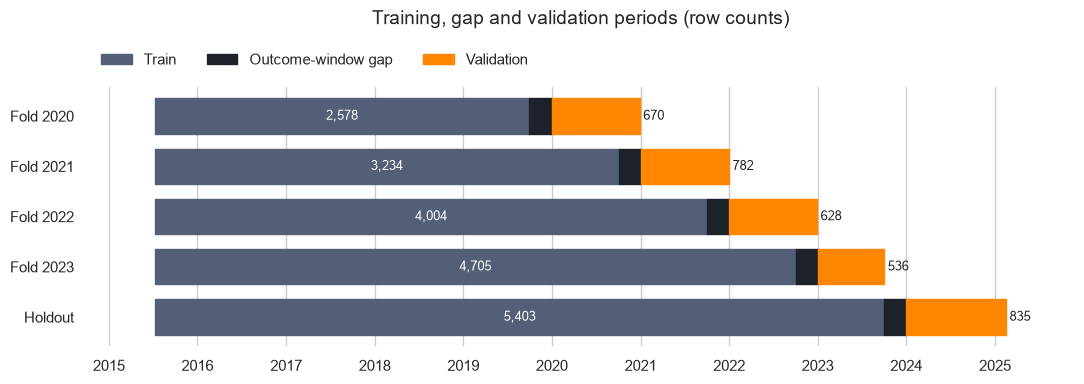

In [586]:
TRAIN_COLOUR, GAP_COLOUR, VAL_COLOUR = "#525f77", "#1d212a", "#ff8600"

plot_rows = [(f"Fold {y}", dev.iloc[tr], dev.iloc[va]) for (tr, va), y in zip(folds, VAL_YEARS)]
plot_rows.append(("Holdout", dev, holdout))

fig, ax = plt.subplots(figsize=(11, 4))

for i, (label, tr, va) in enumerate(plot_rows[::-1]):
    t0, t1 = mdates.date2num(tr["purchase_date"].min()), mdates.date2num(tr["purchase_date"].max())
    v0, v1 = mdates.date2num(va["purchase_date"].min()), mdates.date2num(va["purchase_date"].max())

    ax.broken_barh([(t0, t1 - t0)], (i - 0.35, 0.7), color=TRAIN_COLOUR)
    ax.broken_barh([(t1, v0 - t1)], (i - 0.35, 0.7), color=GAP_COLOUR)
    ax.broken_barh([(v0, v1 - v0)], (i - 0.35, 0.7), color=VAL_COLOUR)

    ax.text((t0 + t1) / 2, i, f"{len(tr):,}", ha="center", va="center", color="white", fontsize=9)
    ax.text(v1 + 15, i, f"{len(va):,}", ha="left", va="center", fontsize=9)

ax.set_yticks(range(len(plot_rows)))
ax.set_yticklabels([r[0] for r in plot_rows[::-1]])
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(axis="y", visible=False)
ax.set_title(
    "Training, gap and validation periods (row counts)",
    pad=45,
)

handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in (TRAIN_COLOUR, GAP_COLOUR, VAL_COLOUR)]
# Place the legend above the plot, away from the timeline bars.
ax.legend(
    handles,
    ["Train", "Outcome-window gap", "Validation"],
    loc="lower left",
    bbox_to_anchor=(0, 1.02),
    ncol=3,
    frameon=False,
)

# Leave space for the validation row-count labels.
ax.margins(x=0.08)

sns.despine(top=True, right=True, left=True, bottom=True)
plt.tight_layout()
plt.show()

## 3.2. How options are compared and how the threshold is chosen

The competition uses F1 on binary predictions. Each model produces probabilities, which are converted to predictions using a threshold. Because different preprocessing options can change those probabilities, each option receives its own threshold.

- **Comparing options:** F1 is the main metric. Customer-level bootstrap intervals help assess differences between options. Log-loss and ROC-AUC are also reported to assess probability quality and ranking without choosing a classification threshold.

- **Choosing the threshold:** predictions from the four validation periods are combined. Thresholds from 0.05 to 0.95 are evaluated in steps of 0.01. We select a tested threshold near the middle of a continuous range whose F1 is within 0.005 of the best grid score. The selected range must contain a best-scoring threshold, with a deterministic rule for ties.

- **Interpreting development scores:** these validation outcomes are used both to choose thresholds and to compare options. The resulting F1 scores guide development and may be optimistic. The bootstrap intervals do not capture all uncertainty from those choices.

- **Reserved holdout:** after selecting the approach, its threshold is fixed using development predictions. The holdout is then evaluated in the modelling stage, without using its outcomes to adjust the model or threshold. Results are also examined separately for previously seen and unseen customers.

- **Baseline:** predicting a repeat purchase for every observation gives F1 = 2p / (1 + p), where p is the positive-class share. Each model is compared with this simple reference.

# 4. Reference model

Section 5 compares treatments for invalid values, missing values, outliers, scaling and encoding. Each comparison needs a fixed starting point, so this section sets up two reference models that every option is measured against:

- **Logistic regression** for the linear side. Scaling, transforms and outliers matter here.
- **Histogram gradient boosting** for the tree side. It handles missing values on its own and scaling is not needed, so it's used to test missing-value handling, encoding and features.

These models provide fixed references for comparing preprocessing options. The broader model comparison follows in the modelling notebooks. Each model is assessed against the all-positive baseline from section 3.

Left out of the inputs: the keys (`ID`, `customer_id`), the purchase date, free-text or near-unique customer fields, and the repair flags. Later on we will test whether the flags help or should also be dropped.

In [587]:
EXCLUDE = ["ID", "customer_id", "purchase_date", target]

# Text columns and how many distinct values each has
text_cols = [
    c for c in dev.columns
    if c not in EXCLUDE and (pd.api.types.is_string_dtype(dev[c]) or dev[c].dtype == object)
]
text_card = pd.DataFrame({
    "distinct": dev[text_cols].nunique(),
    "share_distinct": dev[text_cols].nunique() / dev[text_cols].notna().sum(),
}).sort_values("distinct", ascending=False)
print("Text columns")
display(text_card)

# Numeric columns with few values: some may be codes rather than amounts
num_cols = [
    c for c in dev.select_dtypes("number").columns
    if c not in EXCLUDE and not c.startswith("flag_")
]
low_card = dev[num_cols].nunique()
print("Numeric columns with few distinct values")
display(low_card[low_card <= 15].sort_values().to_frame("distinct"))

Text columns


,distinct,share_distinct
company_name,569,0.105
address,560,0.104
postal_code,490,0.094
street,246,0.110
city,241,0.066
postal_area,183,0.035
municipality,145,0.028
transport_method,76,0.015
commercial_region,31,0.006
island,10,0.003


Numeric columns with few distinct values


,distinct
customer_type,0
invoice_count_current_purchase,5
customer_since_year,9
purchase_count_30d,12


Company name, address, street and postal code are excluded from the reference models because their labels often identify individual customers or very small groups. This creates a risk of memorisation and limited usefulness for unseen customers. The entirely missing customer_type column is also excluded.

A fixed categorical schema is defined from the development set: columns with ten or fewer observed levels are treated as small categorical columns, and the others as large categorical columns. This schema uses development-wide category counts; the encoding values themselves are learned separately within each training fold.

For logistic regression, small categorical columns are one-hot encoded, grouping levels represented by fewer than 20 training observations. Large categorical columns are frequency encoded using their shares among non-missing training values. Missing and unseen labels receive zero.

For histogram gradient boosting, small categorical columns use ordinal codes explicitly marked as categorical inputs. Large categorical columns use frequency encoding. Section 5.5 compares alternative encodings.

In [588]:
FREE_TEXT = ["company_name", "address", "street", "postal_code"]
HIGH_CARD_LIMIT = 10  # more levels than this
RARE_MIN_ROWS = 20    # one-hot levels with fewer rows are grouped together

not_found = [c for c in FREE_TEXT if c not in dev.columns]
print("Names not found:", not_found)

# Columns with no values at all carry no information
empty_cols = [c for c in num_cols + text_cols if dev[c].isna().all()]
print("Empty columns dropped:", empty_cols)

num_features = [c for c in num_cols if c not in empty_cols]
cat_candidates = [c for c in text_cols if c not in FREE_TEXT + empty_cols]

# Split categories by number of levels
levels = dev[cat_candidates].nunique()
high_card = levels[levels > HIGH_CARD_LIMIT].index.tolist()
low_card = levels[levels <= HIGH_CARD_LIMIT].index.tolist()

features = num_features + high_card + low_card
print(f"Numeric: {len(num_features)} | Frequency-encoded: {len(high_card)} | One-hot: {len(low_card)}")
print("Frequency-encoded:", high_card)
print("One-hot:", low_card)


class FrequencyEncoder(BaseEstimator, TransformerMixin):
    """Replace each level with its share of training rows. Missing and unseen levels get 0."""

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.columns_ = list(X.columns)
        self.maps_ = {c: X[c].value_counts(normalize=True).to_dict() for c in self.columns_}
        return self

    def transform(self, X):
        X = pd.DataFrame(X, columns=self.columns_)
        return pd.DataFrame(
            {f"{c}_freq": X[c].map(self.maps_[c]).astype(float).fillna(0.0) for c in self.columns_},
            index=X.index,
        )

    def get_feature_names_out(self, input_features=None):
        return np.array([f"{c}_freq" for c in self.columns_])


def make_reference_models(num, high, low, num_steps=None, high_encoder="frequency"):
    """Both reference pipelines. num_steps replaces the numeric fill and scaling;
    high_encoder picks how the large categorical columns are encoded."""
    if num_steps is None:
        num_steps = [
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ]

    def high_block(scaled):
        # Encoders that turn a level into a number get scaled on the linear side
        if high_encoder == "frequency":
            enc = FrequencyEncoder()
        elif high_encoder == "target":
            enc = TargetEncoder(
                target_type="binary",
                cv=StratifiedKFold(
                    n_splits=5,
                    shuffle=True,
                    random_state=RANDOM_STATE,
                ),
            )
        elif high_encoder == "onehot_rare":
            return OneHotEncoder(
                handle_unknown="infrequent_if_exist", min_frequency=RARE_MIN_ROWS, sparse_output=False
            )
        else:
            raise ValueError(f"unknown high_encoder: {high_encoder!r}")
        return Pipeline([("encode", enc), ("scale", StandardScaler())]) if scaled else enc

    linear_prep = ColumnTransformer([
        ("num", Pipeline(num_steps), num),
        ("high", high_block(scaled=True), high),
        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=RARE_MIN_ROWS), low),
    ], sparse_threshold=0)  # always return a dense matrix

    tree_prep = ColumnTransformer([
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan), low),
        ("high", high_block(scaled=False), high),
        ("num", "passthrough", num),
    ], verbose_feature_names_out=False)

    return {
        "logistic": Pipeline([
            ("prep", linear_prep),
            ("model", LogisticRegression(max_iter=5000)),
        ]),
        "hist_gb": Pipeline([
            ("prep", tree_prep),
            ("model", HistGradientBoostingClassifier(
                categorical_features=list(range(len(low))),  # small categories come first
                random_state=RANDOM_STATE,
            )),
        ]),
    }

reference_models = make_reference_models(num_features, high_card, low_card)

log.record(
    "D15", ", ".join(empty_cols), "drop empty columns",
    "No value in any row, so the column carries no information.",
    len(train_clean), len(test_clean),
    carries={"drop": empty_cols},
)
log.record(
    "D16", "keys, date, free text, flags", "left out of the reference models",
    "Keys and date are not features; free text is near-unique; flags are tested in 5.1.",
    0, 0,
    carries={"drop": EXCLUDE + FREE_TEXT},
)
log.record(
    "D17", "categorical columns", f"one-hot if <= {HIGH_CARD_LIMIT} levels, frequency encoding above",
    "One-hot on every category would add about 700 columns for 5,403 rows.",
    0, 0,
    carries={"one_hot": low_card, "frequency": high_card, "min_frequency": RARE_MIN_ROWS},
)

display(log.to_frame().tail(3))

Names not found: []
Empty columns dropped: ['customer_type']
Numeric: 30 | Frequency-encoded: 5 | One-hot: 7
Frequency-encoded: ['transport_method', 'commercial_region', 'municipality', 'city', 'postal_area']
One-hot: ['payment_type', 'salesperson', 'commercial_zone', 'warehouse', 'document_series', 'country_or_region', 'island']


,step,column,action,reason,rows_train,rows_test
16,D15,customer_type,drop empty columns,"No value in any row, so the column carries no information.",6469,986
17,D16,"keys, date, free text, flags",left out of the reference models,Keys and date are not features; free text is near-unique; flags are tested in 5.1.,0,0
18,D17,categorical columns,"one-hot if <= 10 levels, frequency encoding above","One-hot on every category would add about 700 columns for 5,403 rows.",0,0


## 4.1. Scoring on the folds

Each pipeline is fitted on a fold's training observations and predicts probabilities for its later validation period. Learned preprocessing steps are fitted using that training portion only.

Log-loss and ROC-AUC are calculated separately for each validation period. For F1, the four periods' predictions are combined to select one threshold per option using the procedure in section 3.2. That threshold is then applied when reporting each fold's F1.

Because threshold selection uses these validation outcomes, the reported F1 scores are development estimates and may be optimistic. The reserved holdout provides a later assessment after the approach and threshold have been selected.

The reported lift is the absolute F1 difference between the model and the all-positive baseline for that validation period.

In [589]:
def best_threshold(y, p, tol=0.005):
    """Choose a tested threshold within a continuous near-best F1 range."""
    grid = np.round(np.arange(0.05, 0.951, 0.01), 2)

    # Compute F1 for every threshold.
    y = np.asarray(y).astype(bool)[:, None]
    pred = np.asarray(p)[:, None] >= grid

    tp = (pred & y).sum(axis=0)
    fp = (pred & ~y).sum(axis=0)
    fn = (~pred & y).sum(axis=0)

    f1s = 2 * tp / np.maximum(2 * tp + fp + fn, 1)

    # Identify thresholds within the allowed distance of the best F1.
    near_idx = np.flatnonzero(f1s >= f1s.max() - tol)

    # Split them into continuous ranges on the threshold grid.
    regions = np.split(
        near_idx,
        np.flatnonzero(np.diff(near_idx) > 1) + 1,
    )

    # Only consider ranges containing a best-scoring threshold.
    best_regions = [
        region
        for region in regions
        if np.any(f1s[region] == f1s.max())
    ]

    # Prefer the widest range; break ties using the lower starting threshold.
    chosen = max(
        best_regions,
        key=lambda region: (len(region), -int(region[0])),
    )

    # Select a tested central threshold, using the lower one for even lengths.
    selected_idx = chosen[(len(chosen) - 1) // 2]

    return float(grid[selected_idx]), grid, f1s


def f1_floor(y):
    """F1 of predicting 1 for every row."""
    p = np.mean(y)
    return 2 * p / (1 + p)


def count_kept(model):
    """Columns that reach the final model, after encoding and selection."""
    if hasattr(model, "model_"):  # a model that picks its own columns wraps a fitted pipeline
        return count_kept(model.model_)
    steps = model.named_steps
    if "select" in steps:
        sel = steps["select"]
        if hasattr(sel, "n_components_"):  # PCA
            return int(sel.n_components_)
        return int(sel.get_support().sum())
    return len(steps["prep"].get_feature_names_out())


def score_folds(pipe, data, folds, features, train_filter=None):
    """Fit on each fold, return a per-fold table, the stacked predictions and the threshold.
    train_filter: optional function(train_part) -> boolean mask of training rows to keep."""
    rows, oof = [], []
    for (tr, va), year in zip(folds, VAL_YEARS):
        train_part, val_part = data.iloc[tr], data.iloc[va]
        if train_filter is not None:
            train_part = train_part[train_filter(train_part)]

        model = clone(pipe).fit(train_part[features], train_part[target])
        p = model.predict_proba(val_part[features])[:, 1]
        y = val_part[target].to_numpy()

        # Log-loss of always predicting the training positive rate
        ll = log_loss(y, p)
        ll_floor = log_loss(y, np.full(len(y), train_part[target].mean()))

        oof.append(pd.DataFrame({
            "fold": year, "y": y, "p": p,
            "customer_id": val_part["customer_id"].to_numpy(),  # used by the customer bootstrap
        }))
        rows.append({
            "fold": year, "train_rows": len(train_part), "n_features": count_kept(model),
            "log_loss": ll, "ll_floor": ll_floor, "ll_gain": ll_floor - ll,
            "roc_auc": roc_auc_score(y, p),
        })

    oof = pd.concat(oof, ignore_index=True)
    thr, _, _ = best_threshold(oof["y"], oof["p"])

    # F1 per fold at this model's own threshold
    for row in rows:
        part = oof[oof["fold"] == row["fold"]]
        row["f1"] = f1_score(part["y"], part["p"] >= thr)
        row["floor"] = f1_floor(part["y"])
        row["lift"] = row["f1"] - row["floor"]

    return pd.DataFrame(rows).set_index("fold"), oof, thr

In [590]:
results = {}
for name, pipe in reference_models.items():
    table, oof, thr = score_folds(pipe, dev, folds, features)
    results[name] = {"table": table, "oof": oof, "threshold": thr}

# Per-fold scores for both models
display(pd.concat({name: r["table"] for name, r in results.items()}))

# One line per model: fold averages, plus F1 on the four years stacked
summary = pd.DataFrame({
    name: {
        **r["table"].mean().to_dict(),
        "f1_stacked": f1_score(r["oof"]["y"], r["oof"]["p"] >= r["threshold"]),
        "threshold": r["threshold"],
    }
    for name, r in results.items()
}).T
display(summary[["log_loss", "ll_floor", "ll_gain", "roc_auc", "f1", "f1_stacked", "floor", "lift", "threshold"]])

train_rows  n_features  log_loss  ll_floor  ll_gain  roc_auc  \
         fold                                                                 
logistic 2020        2578          66     0.608     0.678    0.070    0.741   
         2021        3234          69     0.546     0.688    0.142    0.793   
         2022        4004          72     0.588     0.706    0.118    0.788   
         2023        4705          74     0.558     0.683    0.125    0.778   
hist_gb  2020        2578          42     0.658     0.678    0.019    0.727   
         2021        3234          42     0.551     0.688    0.137    0.794   
         2022        4004          42     0.599     0.706    0.107    0.774   
         2023        4705          42     0.615     0.683    0.068    0.761   

                 f1  floor   lift  
         fold                      
logistic 2020 0.754  0.745  0.009  
         2021 0.743  0.709  0.034  
         2022 0.686  0.649  0.037  
         2023 0.765  0.728  0.036  
hist_gb  2020 0.742  0.745 -0.003  
         2021 0.759  0.709  0.051  
         2022 0.701  0.649  0.052  
         2023 0.748  0.728  0.020

,log_loss,ll_floor,ll_gain,roc_auc,f1,f1_stacked,floor,lift,threshold
logistic,0.575,0.689,0.114,0.775,0.737,0.737,0.708,0.029,0.320
hist_gb,0.606,0.689,0.083,0.764,0.738,0.739,0.708,0.030,0.260


The curves show how F1 changes with the classification threshold across the combined validation predictions. A broad, flat region indicates less sensitivity to the exact threshold on these observations, although it does not guarantee stability on future data.

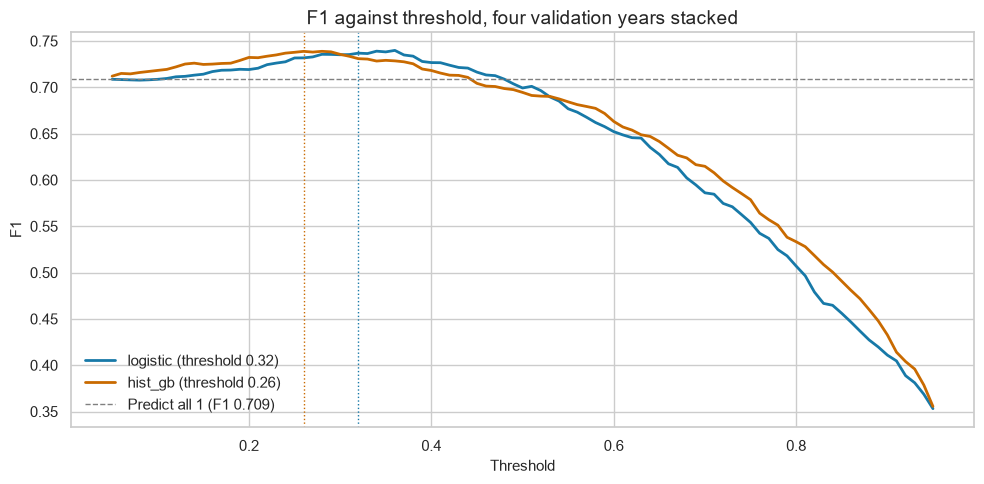

In [591]:
fig, ax = plt.subplots(figsize=(10, 5))
colours = {"logistic": "#1779A8", "hist_gb": "#C96A00"}

for name, r in results.items():
    _, grid, f1s = best_threshold(r["oof"]["y"], r["oof"]["p"])
    ax.plot(grid, f1s, color=colours[name], lw=2, label=f"{name} (threshold {r['threshold']:.2f})")
    ax.axvline(r["threshold"], color=colours[name], ls=":", lw=1)

floor = f1_floor(results["logistic"]["oof"]["y"])
ax.axhline(floor, color="grey", ls="--", lw=1, label=f"Predict all 1 (F1 {floor:.3f})")

ax.set_xlabel("Threshold")
ax.set_ylabel("F1")
ax.set_title("F1 against threshold, four validation years stacked")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

At the selected thresholds, stacked validation F1 is approximately 0.737 for logistic regression and 0.739 for histogram gradient boosting. Both improve on the all-positive baseline by about 0.03. Their small F1 difference alone does not establish that one model is better.

The selected thresholds are 0.32 for logistic regression and 0.26 for histogram gradient boosting. These are chosen from continuous near-best ranges using the rule in section 3.2.

Logistic regression has lower mean log-loss (0.575 versus 0.606) and higher mean ROC-AUC (0.775 versus 0.764). Histogram gradient boosting scores slightly below the all-positive F1 baseline in 2020, while logistic regression exceeds it in every fold.

These are development results: the validation outcomes were also used to choose thresholds. The selected approach will receive a separate assessment on the reserved holdout.

# 5. Treatment comparisons

Preprocessing options are compared using the same four chronological folds and reference models. Learned treatment parameters, such as imputation values, scaling statistics and encoding maps, are fitted on each fold's training observations.

Scaling, numeric transformations and outlier treatments are evaluated on logistic regression. Trees generally depend less on feature scale, but clipping, removing observations and histogram binning can still affect their predictions. These experiments therefore do not establish that such treatments are irrelevant to tree models.

Invalid-value treatments, categorical encodings and customer-table features are evaluated on both reference models.

An alternative replaces the reference when all three conditions hold:

1. Its F1 on the combined validation predictions is higher, using each option's selected threshold.
2. The lower bound of the 95% customer-bootstrap interval for F1(alternative) minus F1(reference) is above zero.
3. Its F1 is lower than the reference in no more than one of the four validation periods.

The bootstrap resamples whole customers, keeping their observations together. Thresholds remain fixed during resampling. These intervals therefore assess differences between the selected predictions, without capturing all uncertainty from threshold selection or testing many alternatives.

Passing this rule provides exploratory support for an option. An interval containing zero means no clear difference was detected, rather than proving equivalent performance. If an alternative does not pass, the reference is retained.

Log-loss, its improvement over the constant-probability baseline and ROC-AUC are reported alongside F1.

In [592]:
def fast_f1(y, pred):
    """F1 for boolean arrays, quicker than sklearn inside the bootstrap loop."""
    tp = np.sum(y & pred)
    fp = np.sum(~y & pred)
    fn = np.sum(y & ~pred)
    return 2 * tp / (2 * tp + fp + fn) if tp else 0.0


def bootstrap_f1_diff(
    oof_ref,
    oof_opt,
    thr_ref,
    thr_opt,
    n_boot=2000,
    seed=RANDOM_STATE,
):
    """95% interval of F1(option) - F1(reference), resampling whole customers."""
    assert (
        oof_ref["customer_id"].to_numpy()
        == oof_opt["customer_id"].to_numpy()
    ).all()

    y = oof_ref["y"].to_numpy().astype(bool)
    pred_ref = oof_ref["p"].to_numpy() >= thr_ref
    pred_opt = oof_opt["p"].to_numpy() >= thr_opt

    # Row positions of each customer.
    groups = list(oof_ref.groupby("customer_id").indices.values())
    rng = np.random.default_rng(seed)

    diffs = np.empty(n_boot)

    for b in range(n_boot):
        pick = rng.integers(0, len(groups), len(groups))
        rows = np.concatenate([groups[i] for i in pick])

        diffs[b] = (
            fast_f1(y[rows], pred_opt[rows])
            - fast_f1(y[rows], pred_ref[rows])
        )

    return np.percentile(diffs, [2.5, 97.5])


def judge(runs, reference, tie_rule=False):
    """Apply the exploratory decision rule to scored options.

    With tie_rule=True, prefer fewer columns when the bootstrap interval
    includes zero and the option is worse in no more than two folds.
    This preference does not establish equivalent performance.
    """
    ref_table, ref_oof, ref_thr = runs[reference]

    ref_f1 = fast_f1(
        ref_oof["y"].to_numpy().astype(bool),
        ref_oof["p"].to_numpy() >= ref_thr,
    )
    ref_n = ref_table["n_features"].mean()

    rows = []

    for name, (table, oof, thr) in runs.items():
        f1_all = fast_f1(
            oof["y"].to_numpy().astype(bool),
            oof["p"].to_numpy() >= thr,
        )

        folds_worse = int((table["f1"] < ref_table["f1"]).sum())
        n = table["n_features"].mean()

        if name == reference:
            lo, hi, verdict = np.nan, np.nan, "reference"
        else:
            lo, hi = bootstrap_f1_diff(
                ref_oof, oof, ref_thr, thr
            )

            if lo > 0 and folds_worse <= 1:
                verdict = "better"
            elif hi < 0:
                verdict = "worse"
            elif (
                tie_rule
                and lo <= 0 <= hi
                and n < ref_n
                and folds_worse <= 2
            ):
                verdict = "no clear difference; fewer columns preferred"
            else:
                verdict = "no clear difference"

        rows.append({
            "option": name,
            "n_features": n,
            "f1_stacked": f1_all,
            "f1_diff": f1_all - ref_f1,
            "ci_low": lo,
            "ci_high": hi,
            "folds_worse": folds_worse,
            "threshold": thr,
            "log_loss": table["log_loss"].mean(),
            "ll_gain": table["ll_gain"].mean(),
            "roc_auc": table["roc_auc"].mean(),
            "verdict": verdict,
        })

    return pd.DataFrame(rows).set_index("option")


def compare_options(model_name, options, reference, folds):
    """Build each option's pipeline, score it and apply the decision rule.

    Each option is a dict; omitted settings use the current reference setup.
    """
    runs = {}

    for name, spec in options.items():
        s = {
            "num": num_features,
            "extra_num": [],
            "high": high_card,
            "low": low_card,
            "num_steps": None,
            "train_filter": None,
            "high_encoder": "frequency",
            **spec,
        }

        num = s["num"] + s["extra_num"]

        pipe = make_reference_models(
            num,
            s["high"],
            s["low"],
            s["num_steps"],
            s["high_encoder"],
        )[model_name]

        runs[name] = score_folds(
            pipe,
            s["data"],
            folds,
            num + s["high"] + s["low"],
            s["train_filter"],
        )

    return judge(runs, reference), runs

## 5.1. Invalid values

Section 2.4 reconstructed purchase-history values using relationships between the recorded fields, assuming the supporting totals, counts and dates are reliable. Annual-spending sign corrections additionally assume a sign error where reversing it satisfies the spending bounds. We now compare this approach with retaining or blanking the inconsistent values, with and without repair flags.

- **keep:** the values as they were before the repair, errors included.
- **blank:** every value the repair changed becomes missing. Values the repair filled from missing stay missing.
- **blank_flag:** as blank, plus one column per repaired field marking the rows that were blanked.
- **rebuild:** the repaired data from section 2.4. This is the reference.
- **rebuild_flag:** the repaired data plus the repair flags from section 2.4.

The placeholders from 2.3 (-4 and one billion) are missing values in every option. They aren't real measurements, so keeping them isn't a fair option.

The rebuilt version is the reference because its rules were checked against the data in 2.4. The other options have to show they do better.

In [593]:
REPAIR_COLS = [
    "prior_mean_purchase_value", "prior_min_purchase_value", "prior_max_purchase_value",
    "spend_365d", "prior_mean_gap_days", "days_since_previous_purchase",
]
REPAIR_FLAGS = ["flag_mean_repaired", "flag_max_invalid", "flag_spend365_repaired", "flag_gap_rebuilt"]

def to_dev(df):
    return df[df["purchase_date"] < DEV_END].reset_index(drop=True)

# Data before the repair, same rows and order as dev
dev_keep = to_dev(train_pre_repair)
assert dev_keep["ID"].equals(dev["ID"]), "Row order differs between versions"

# Blank: values the repair changed become missing; values it filled stay missing
dev_blank = dev_keep.copy()
blank_flags = []
for col in REPAIR_COLS:
    before = dev_keep[col].to_numpy(dtype=float)
    after = dev[col].to_numpy(dtype=float)
    changed = ~np.isnan(before) & ~np.isclose(before, after, atol=TOL)
    print(f"{col:<32} blanked: {changed.sum()}")
    if changed.any():
        dev_blank.loc[changed, col] = np.nan
        flag = f"flag_{col}_blanked"
        dev_blank[flag] = changed.astype(int)
        blank_flags.append(flag)

options_51 = {
    "keep": {"data": dev_keep},
    "blank": {"data": dev_blank},
    "blank_flag": {"data": dev_blank, "extra_num": blank_flags},
    "rebuild": {"data": dev},
    "rebuild_flag": {"data": dev, "extra_num": REPAIR_FLAGS},
}

prior_mean_purchase_value        blanked: 47
prior_min_purchase_value         blanked: 0
prior_max_purchase_value         blanked: 41
spend_365d                       blanked: 52
prior_mean_gap_days              blanked: 0
days_since_previous_purchase     blanked: 0


In [594]:
results_51 = {}
for model_name in ["logistic", "hist_gb"]:
    table, runs = compare_options(model_name, options_51, "rebuild", folds)
    results_51[model_name] = {"table": table, "runs": runs}
    print(f"\n{model_name}")
    display(table)


logistic


,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
keep,70.250,0.736,-0.001,-0.008,0.004,2,0.330,0.578,0.110,0.773,no clear difference
blank,70.250,0.735,-0.002,-0.007,0.002,3,0.330,0.573,0.116,0.776,no clear difference
blank_flag,73.250,0.733,-0.004,-0.010,0.000,4,0.330,0.577,0.112,0.773,no clear difference
rebuild,70.250,0.737,0.000,NaN,NaN,0,0.320,0.575,0.114,0.775,reference
rebuild_flag,74.250,0.738,0.001,-0.005,0.006,2,0.330,0.577,0.112,0.772,no clear difference



hist_gb


,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
keep,42.000,0.730,-0.008,-0.018,0.002,3,0.240,0.613,0.076,0.760,no clear difference
blank,42.000,0.729,-0.010,-0.021,-0.000,2,0.280,0.612,0.077,0.763,worse
blank_flag,45.000,0.732,-0.007,-0.020,0.004,3,0.310,0.613,0.076,0.760,no clear difference
rebuild,42.000,0.739,0.000,NaN,NaN,0,0.260,0.606,0.083,0.764,reference
rebuild_flag,46.000,0.730,-0.009,-0.018,-0.000,3,0.250,0.609,0.080,0.761,worse


Reconstruction without repair flags is retained. For logistic regression, no alternative passes the improvement rule: all bootstrap intervals include zero. Adding repair flags increases F1 by approximately 0.001, without clear evidence of improvement.

For histogram gradient boosting, reconstruction gives the highest stacked F1 (0.739) and the lowest mean log-loss (0.606). Blanking values and adding flags to reconstructed values score lower, with bootstrap intervals entirely below zero. Retaining the inconsistent values and blanking with flags also score lower, but their intervals include zero.

These comparisons support retaining reconstruction under the stated assumptions. Repair flags provide no clear improvement, so they are excluded from the model inputs.

In [595]:
log.record(
    "D18",
    ", ".join(REPAIR_COLS),
    "keep rebuilt values, no repair flags",
    (
        "No alternative passed the improvement rule. "
        "Reconstruction had the highest stacked F1 and lowest mean "
        "log-loss for histogram gradient boosting. Blanking and "
        "reconstruction with flags scored lower with bootstrap "
        "intervals below zero; other differences were inconclusive."
    ),
    0,
    0,
    carries={"invalid_values": "rebuild", "flags": False},
)

display(log.to_frame().tail(1))

,step,column,action,reason,rows_train,rows_test
19,D18,"prior_mean_purchase_value, prior_min_purchase_value, prior_max_purchase_value, spend_365d, prior...","keep rebuilt values, no repair flags",No alternative passed the improvement rule. Reconstruction had the highest stacked F1 and lowest...,0,0


## 5.2. Missing values

Some missing history values reflect insufficient previous purchases. For example, a customer with no previous purchases has no historical mean purchase value or previous-purchase interval. Calculating historical standard deviations requires additional observations.

Other values remain missing because they were unavailable or could not be reconstructed reliably.

Five numeric missing-value treatments are compared using logistic regression:

- **median:** fill with each column's training median. This is the reference.
- **mean:** fill with each column's training mean.
- **structural:** add first-purchase and single-purchase indicators, fill missing history values with zero where insufficient history explains their absence, then median-impute the remaining missing values. These zeros are modelling placeholders rather than observed measurements.
- **knn:** fill using five neighbouring training observations, with scaling fitted before imputation because distances depend on feature scale.
- **iterative:** estimate missing values from the other numeric columns through repeated modelling steps.

These treatments are evaluated on logistic regression. Histogram gradient boosting retains its native missing-value handling as the reference approach; this does not establish that explicit imputation could never improve it.

Learned imputation parameters are fitted separately within each training fold. Categorical missing-value handling remains unchanged during this comparison.

In [596]:
HISTORY_COLS = [
    "prior_mean_purchase_value",
    "prior_min_purchase_value",
    "prior_max_purchase_value",
    "prior_std_purchase_value",
    "days_since_previous_purchase",
    "prior_mean_gap_days",
    "prior_std_gap_days",
]

STRUCT_FLAGS = ["is_first_purchase", "is_single_purchase"]


def add_structural(df):
    """Mark limited history and zero-fill structurally missing values only."""
    df = df.copy()
    count = df["prior_purchase_count"]

    df["is_first_purchase"] = (count == 0).astype(int)
    df["is_single_purchase"] = (count == 1).astype(int)

    # These statistics require at least one previous purchase.
    needs_one = [
        "prior_mean_purchase_value",
        "prior_min_purchase_value",
        "prior_max_purchase_value",
        "days_since_previous_purchase",
    ]
    no_history = count == 0

    df.loc[no_history, needs_one] = (
        df.loc[no_history, needs_one].fillna(0.0)
    )

    # A sample purchase-value standard deviation needs two purchases.
    # A mean gap also needs two purchases, providing one historical gap.
    needs_two = [
        "prior_std_purchase_value",
        "prior_mean_gap_days",
    ]
    fewer_than_two = count.notna() & (count >= 0) & (count < 2)

    df.loc[fewer_than_two, needs_two] = (
        df.loc[fewer_than_two, needs_two].fillna(0.0)
    )

    # A sample gap standard deviation needs two gaps:
    # at least three previous purchases.
    fewer_than_three = count.notna() & (count >= 0) & (count < 3)

    df.loc[fewer_than_three, "prior_std_gap_days"] = (
        df.loc[fewer_than_three, "prior_std_gap_days"].fillna(0.0)
    )

    return df


dev_struct = add_structural(dev)

missing_summary = pd.DataFrame({
    "missing_before": dev[HISTORY_COLS].isna().sum(),
    "missing_after_structural_fill": (
        dev_struct[HISTORY_COLS].isna().sum()
    ),
})

display(missing_summary)

options_52 = {
    "median": {
        "data": dev,
        "num_steps": [
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ],
    },
    "mean": {
        "data": dev,
        "num_steps": [
            ("impute", SimpleImputer(strategy="mean")),
            ("scale", StandardScaler()),
        ],
    },
    "structural": {
        "data": dev_struct,
        "extra_num": STRUCT_FLAGS,
        "num_steps": [
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ],
    },
    "knn": {
        "data": dev,
        "num_steps": [
            ("scale", StandardScaler()),
            ("impute", KNNImputer(n_neighbors=5)),
        ],
    },
    "iterative": {
        "data": dev,
        "num_steps": [
            (
                "impute",
                IterativeImputer(
                    max_iter=30,
                    random_state=RANDOM_STATE,
                ),
            ),
            ("scale", StandardScaler()),
        ],
    },
}

,missing_before,missing_after_structural_fill
prior_mean_purchase_value,568,0
prior_min_purchase_value,568,0
prior_max_purchase_value,606,38
prior_std_purchase_value,977,0
days_since_previous_purchase,576,8
prior_mean_gap_days,985,8
prior_std_gap_days,1310,0


In [597]:
table_52, runs_52 = compare_options("logistic", options_52, "median", folds)
display(table_52)

,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
median,70.250,0.737,0.000,NaN,NaN,0,0.320,0.575,0.114,0.775,reference
mean,70.250,0.737,0.001,-0.006,0.006,2,0.340,0.575,0.114,0.775,no clear difference
structural,72.250,0.737,0.000,-0.007,0.006,2,0.340,0.577,0.112,0.774,no clear difference
knn,70.250,0.737,0.000,-0.005,0.005,1,0.320,0.576,0.113,0.775,no clear difference
iterative,70.250,0.735,-0.002,-0.006,0.002,2,0.320,0.576,0.113,0.774,no clear difference


Median imputation is retained. All alternatives have bootstrap intervals containing zero, so none shows a clear F1 improvement under the exploratory decision rule.

Stacked F1 is approximately 0.737 for median, mean, structural and KNN imputation, and 0.735 for iterative imputation. Mean log-loss and ROC-AUC also differ little across the tested options.

The structural treatment now includes both historical standard-deviation fields, but adding it with the two history indicators provides no clear improvement in this comparison. This does not establish that the indicators would be unhelpful in other model configurations.

Median imputation is a simple reference that the tested alternatives did not clearly improve upon. Any convergence warning from iterative imputation should be considered when interpreting that option; its results alone cannot establish what a longer run would achieve.

In [598]:
log.record(
    "D19",
    "numeric columns",
    "fill missing values with the training median",
    (
        "Mean, structural, KNN and iterative imputation did not "
        "clearly improve F1 under the exploratory decision rule. "
        "All comparison intervals included zero. Median imputation "
        "was retained as the simple reference."
    ),
    0,
    0,
    carries={"numeric_fill": "median"},
)

display(log.to_frame().tail(1))

,step,column,action,reason,rows_train,rows_test
20,D19,numeric columns,fill missing values with the training median,"Mean, structural, KNN and iterative imputation did not clearly improve F1 under the exploratory ...",0,0


## 5.3. Outliers

Spending and purchase-count variables have long right tails. Large values may represent genuine customer behaviour, so being statistically unusual is not enough to justify removing them.

Three treatments are compared using logistic regression:

- **keep:** retain the repaired values without additional clipping or filtering. This is the reference.
- **winsorise:** clip numeric values to the 1st and 99th percentiles learned from each fold's training observations. Limits are calculated before median imputation.
- **IQR drop:** remove training observations lying outside the 1.5 × IQR fences in any assessed numeric column. Columns with zero IQR are skipped. Missing values do not themselves trigger removal, and validation observations are preserved.

The IQR rule tests an aggressive filtering approach. Removing observations across many columns can discard a substantial share of the data, including valid purchases. Its effect is measured rather than assumed.

These treatments are tested on logistic regression here. Trees generally depend less on feature scale, but clipping, removing observations and histogram binning can still affect their predictions.

In [599]:
class Winsorizer(BaseEstimator, TransformerMixin):
    """Clip each column to quantiles learned on the training rows. Missing values stay missing."""

    def __init__(self, lower=0.01, upper=0.99):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.low_ = np.nanquantile(X, self.lower, axis=0)
        self.high_ = np.nanquantile(X, self.upper, axis=0)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.low_, self.high_)

    def get_feature_names_out(self, input_features=None):
        return input_features

def iqr_keep(train_part, k=1.5):
    """True for training rows with no value beyond the IQR fences."""
    X = train_part[num_features]
    q1, q3 = X.quantile(0.25), X.quantile(0.75)
    iqr = q3 - q1
    use = iqr[iqr > 0].index  # skip columns where the fences collapse
    outside = (X[use] < q1[use] - k * iqr[use]) | (X[use] > q3[use] + k * iqr[use])
    return ~outside.any(axis=1).to_numpy()


default_steps = [
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
]

options_53 = {
    "keep": {"data": dev, "num_steps": default_steps},
    "winsorise": {"data": dev, "num_steps": [
        ("clip", Winsorizer(0.01, 0.99)),  # limits from raw training values
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]},
    "iqr_drop": {"data": dev, "num_steps": default_steps, "train_filter": iqr_keep},
}

In [600]:
table_53, runs_53 = compare_options("logistic", options_53, "keep", folds)
display(table_53)

# How many training rows the IQR rule removed in each fold
kept = runs_53["iqr_drop"][0]["train_rows"]
full = runs_53["keep"][0]["train_rows"]
display(pd.DataFrame({"train_rows": full, "after_iqr": kept, "share_dropped": 1 - kept / full}))

,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
keep,70.250,0.737,0.000,NaN,NaN,0,0.320,0.575,0.114,0.775,reference
winsorise,70.250,0.737,-0.000,-0.006,0.006,3,0.340,0.572,0.116,0.770,no clear difference
iqr_drop,66.000,0.710,-0.027,-0.042,-0.013,4,0.290,0.845,-0.142,0.733,worse


,train_rows,after_iqr,share_dropped
fold,,,
2020,2578,1081,0.581
2021,3234,1275,0.606
2022,4004,1724,0.569
2023,4705,1987,0.578


The repaired values are retained without additional outlier treatment. Winsorising gives approximately the same stacked F1 as the reference (0.737), with a bootstrap interval spanning zero. Its mean log-loss is slightly lower, while ROC-AUC is lower, so the secondary metrics give mixed evidence.

The IQR rule removes approximately 57–61% of training observations across folds. Stacked F1 falls from 0.737 to 0.710, with a bootstrap interval for the difference entirely below zero. F1 is lower in all four validation periods, and mean log-loss is worse than the fold-specific constant-probability baseline.

These results support rejecting this aggressive filtering rule. They do not establish that every extreme value is correct or that other outlier treatments would be ineffective.

In [601]:
log.record(
    "D20",
    "numeric columns",
    "retain repaired values without additional outlier treatment",
    (
        "Winsorising at the 1st and 99th percentiles showed no clear "
        "F1 improvement. The IQR rule removed approximately 57–61% "
        "of training observations and reduced F1 in every fold, "
        "with the bootstrap interval for the difference below zero."
    ),
    0,
    0,
    carries={
        "outliers": "keep",
        "rule_tested": ["winsorize 1/99", "drop IQR 1.5"],
    },
)

display(log.to_frame().tail(1))

,step,column,action,reason,rows_train,rows_test
21,D20,numeric columns,retain repaired values without additional outlier treatment,Winsorising at the 1st and 99th percentiles showed no clear F1 improvement. The IQR rule removed...,0,0


## 5.4. Transformations and scaling

Five numeric preprocessing options are compared using logistic regression:

- **standard:** centre each column on its training mean and divide by its training standard deviation.
- **robust:** centre on the training median and scale by the training interquartile range.
- **minmax:** scale using the training minimum and maximum.
- **log1p + standard:** apply log1p to eligible right-skewed numeric columns, then impute and standardise.
- **yeo-johnson:** impute, apply a learned power transformation and standardise. This transformation supports zero and negative values.

For log1p, eligible columns are selected separately within each training fold: their observed training values must be non-negative and their training skewness must exceed 1. random_noise and customer_since_year are excluded from this transformation. The selected columns are then fixed when transforming that fold's validation data.

All learned transformation, imputation and scaling parameters use training-fold observations only. Frequency-encoded categorical columns retain standard scaling in every option.

These comparisons concern the regularised logistic regression used here. Changing feature scale can change how its regularisation penalty affects coefficients.

In [602]:
LOG_SKIP = ["random_noise", "customer_since_year"]


class Log1pColumns(BaseEstimator, TransformerMixin):
    """Learn eligible log1p columns from training data only."""

    def __init__(self, skew_threshold=1.0, skip=None):
        self.skew_threshold = skew_threshold
        self.skip = skip

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.columns_in_ = list(X.columns)

        excluded = set(self.skip) if self.skip is not None else set()

        candidates = [
            col
            for col in self.columns_in_
            if col not in excluded
        ]

        # These statistics use only the rows passed to fit.
        minimum = X[candidates].min()
        skewness = X[candidates].skew()

        self.columns_ = [
            col
            for col in candidates
            if minimum[col] >= 0
            and skewness[col] > self.skew_threshold
        ]

        return self

    def transform(self, X):
        X = pd.DataFrame(X, columns=self.columns_in_).copy()

        # Preserve the existing safeguard: later negative values in
        # selected columns are clipped to zero before applying log1p.
        if self.columns_:
            X[self.columns_] = np.log1p(
                X[self.columns_].clip(lower=0)
            )

        return X

    def get_feature_names_out(self, input_features=None):
        return np.array(self.columns_in_, dtype=object)


def median_then(scaler):
    return [
        ("impute", SimpleImputer(strategy="median")),
        ("scale", scaler),
    ]


options_54 = {
    "standard": {
        "data": dev,
        "num_steps": median_then(StandardScaler()),
    },
    "robust": {
        "data": dev,
        "num_steps": median_then(RobustScaler()),
    },
    "minmax": {
        "data": dev,
        "num_steps": median_then(MinMaxScaler()),
    },
    "log1p_standard": {
        "data": dev,
        "num_steps": [
            (
                "log",
                Log1pColumns(
                    skew_threshold=1.0,
                    skip=LOG_SKIP,
                ),
            ),
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ],
    },
    "yeo_johnson": {
        "data": dev,
        "num_steps": [
            ("impute", SimpleImputer(strategy="median")),
            (
                "power",
                PowerTransformer(
                    method="yeo-johnson",
                    standardize=True,
                ),
            ),
        ],
    },
}

In [603]:
table_54, runs_54 = compare_options("logistic", options_54, "standard", folds)
display(table_54)

,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
standard,70.250,0.737,0.000,NaN,NaN,0,0.320,0.575,0.114,0.775,reference
robust,70.250,0.737,0.000,-0.001,0.002,1,0.320,0.575,0.114,0.775,no clear difference
minmax,70.250,0.737,-0.000,-0.010,0.008,3,0.360,0.570,0.118,0.770,no clear difference
log1p_standard,70.250,0.736,-0.000,-0.010,0.007,2,0.350,0.566,0.123,0.773,no clear difference
yeo_johnson,70.250,0.737,0.001,-0.008,0.009,2,0.360,0.568,0.121,0.771,no clear difference


Standard scaling without an additional transformation is retained. All alternatives have bootstrap intervals containing zero, so none shows a clear F1 improvement under the exploratory decision rule.

Stacked F1 remains approximately 0.736–0.737 across the tested options. Log1p reduces mean log-loss from 0.575 to 0.566, while Yeo–Johnson reduces it to 0.568. These results suggest improved probability quality under log-loss, without a clear improvement in thresholded F1.

Changing scale can affect regularised logistic regression because it changes how the penalty acts on coefficients. The similar scores observed here are an empirical result, rather than evidence that scaling cannot affect the model.

Since F1 is the primary selection metric, standard scaling is retained. The lower log-loss makes the transformations reasonable candidates for later model-specific comparisons, without guaranteeing an improvement.

In [604]:
log.record(
    "D21",
    "numeric columns",
    "standard scaling, no additional transformation",
    (
        "No alternative passed the exploratory F1 improvement rule; "
        "all comparison intervals included zero. Log1p reduced mean "
        "log-loss from approximately 0.575 to 0.566, but did not "
        "clearly improve F1. Log-transform columns were selected "
        "separately within each training fold."
    ),
    0,
    0,
    carries={
        "scaler": "standard",
        "transform": "none",
        "log1p_selection_tested": {
            "scope": "training fold only",
            "minimum_observed_value": 0,
            "skewness_above": 1.0,
            "excluded_columns": LOG_SKIP,
        },
    },
)

display(log.to_frame().tail(1))

,step,column,action,reason,rows_train,rows_test
22,D21,numeric columns,"standard scaling, no additional transformation",No alternative passed the exploratory F1 improvement rule; all comparison intervals included zer...,0,0


## 5.5. Encoding the large categorical columns

Five columns have more than ten observed levels in the development schema: transport_method, commercial_region, municipality, city and postal_area.

Four approaches are compared using both reference models:

- **frequency:** replace each label with its frequency among non-missing training observations. Missing and unseen labels receive zero. This is the reference.
- **target:** use smoothed training target rates. Internal cross-fitting prevents a training row's own target from directly determining its encoding. However, those internal splits are not chronological or grouped by customer. This limits how closely the encoder's training procedure reflects our temporal validation design.
- **rare + one-hot:** create indicator columns, grouping labels represented by fewer than 20 training observations into an infrequent category.
- **coarse geography:** remove city, postal_area and municipality while retaining the broader geographic fields. The remaining large categorical columns retain frequency encoding.

Every encoder is fitted within the outer training fold, without using the outer validation targets. Small categorical columns retain their existing treatment: one-hot encoding for logistic regression and native categorical handling through ordinal codes for histogram gradient boosting.

The coarse-geography option changes which features are included, as well as reducing the encoded input size. Any promising result therefore needs confirmation during feature selection.

In [605]:
COARSE_DROP = ["city", "postal_area", "municipality"]
coarse_high = [c for c in high_card if c not in COARSE_DROP]
print("Coarse geography keeps:", coarse_high)

options_55 = {
    "frequency": {"data": dev},
    "target": {"data": dev, "high_encoder": "target"},
    "onehot_rare": {"data": dev, "high_encoder": "onehot_rare"},
    "coarse_geo": {"data": dev, "high": coarse_high},
}

results_55 = {}
for model_name in ["logistic", "hist_gb"]:
    table, runs = compare_options(model_name, options_55, "frequency", folds)
    results_55[model_name] = {"table": table, "runs": runs}
    print(f"\n{model_name}")
    display(table)

Coarse geography keeps: ['transport_method', 'commercial_region']

logistic


,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
frequency,70.250,0.737,0.000,NaN,NaN,0,0.320,0.575,0.114,0.775,reference
target,70.250,0.736,-0.001,-0.009,0.007,3,0.320,0.571,0.118,0.776,no clear difference
onehot_rare,203.250,0.732,-0.005,-0.016,0.009,2,0.270,0.593,0.096,0.759,no clear difference
coarse_geo,67.250,0.739,0.002,-0.003,0.009,1,0.310,0.573,0.116,0.777,no clear difference



hist_gb


,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
frequency,42.000,0.739,0.000,NaN,NaN,0,0.260,0.606,0.083,0.764,reference
target,42.000,0.734,-0.004,-0.015,0.006,3,0.280,0.604,0.085,0.764,no clear difference
onehot_rare,175.000,0.734,-0.004,-0.017,0.007,4,0.280,0.608,0.081,0.758,no clear difference
coarse_geo,39.000,0.735,-0.003,-0.018,0.009,2,0.340,0.596,0.093,0.767,no clear difference


Frequency encoding is retained for the large categorical columns. None of the alternatives passes the exploratory F1 improvement rule for either model; every comparison interval includes zero.

Rare-category one-hot encoding substantially increases the number of inputs and gives lower stacked F1 for both models. For logistic regression, its mean log-loss is also higher (0.593 versus 0.575). These results do not support adopting it in the tested configuration.

Removing the three fine-geography fields gives mixed results. Logistic regression has slightly higher F1 and ROC-AUC, while histogram gradient boosting has lower F1 but improved log-loss and ROC-AUC. Neither F1 difference is clear under the bootstrap rule.

Fine geography therefore remains a feature-selection candidate. Its removal must be reassessed in the final configuration, including after random_noise is excluded.

The preprocessing comparisons so far identify no clear F1 improvement over the reference treatments. This does not establish that the alternatives are equivalent or that further preprocessing cannot help.

In [606]:
log.record(
    "D22",
    ", ".join(high_card),
    "keep frequency encoding",
    (
        "No alternative passed the exploratory F1 improvement rule "
        "for either model; all comparison intervals included zero. "
        "Removing fine geography gave mixed results and remains "
        "a candidate for reassessment in the final configuration."
    ),
    0,
    0,
    carries={
        "high_card_encoding": "frequency",
        "coarse_geo_candidate_drop": COARSE_DROP,
    },
)

display(log.to_frame().tail(1))

,step,column,action,reason,rows_train,rows_test
23,D22,"transport_method, commercial_region, municipality, city, postal_area",keep frequency encoding,No alternative passed the exploratory F1 improvement rule for either model; all comparison inter...,0,0


## 5.6. Customer-table fields

The customer table contributes geographic attributes and the recorded customer start year. This section tests whether the customer attributes currently included in the reference models improve predictions beyond the purchase features.

Three configurations are compared using both reference models:

- **all:** purchase features plus the customer attributes retained in the reference setup.
- **no customer table:** purchase features only.
- **since year only:** purchase features plus customer_since_year.

The all configuration does not include every original customer-table column: identifiers, near-unique text fields and the entirely missing customer_type field remain excluded.

This comparison assesses the customer attributes as a group. It does not establish the individual contribution of each geographic field.

In [607]:
# Columns that came from the customer table
customer_fields = [c for c in clientes.columns if c != "customer_id"]

num_purchase = [c for c in num_features if c not in customer_fields]
high_purchase = [c for c in high_card if c not in customer_fields]
low_purchase = [c for c in low_card if c not in customer_fields]

print("Customer fields in use:", [c for c in features if c in customer_fields])
print("Purchase-only inputs:", len(num_purchase), "numeric,", len(high_purchase), "large and",
      len(low_purchase), "small categorical")

options_56 = {
    "all": {"data": dev},
    "no_customer_table": {"data": dev, "num": num_purchase, "high": high_purchase, "low": low_purchase},
    "since_year_only": {
        "data": dev, "num": num_purchase + ["customer_since_year"],
        "high": high_purchase, "low": low_purchase,
    },
}

results_56 = {}
for model_name in ["logistic", "hist_gb"]:
    table, runs = compare_options(model_name, options_56, "all", folds)
    results_56[model_name] = {"table": table, "runs": runs}
    print(f"\n{model_name}")
    display(table)

Customer fields in use: ['customer_since_year', 'commercial_region', 'municipality', 'city', 'postal_area', 'country_or_region', 'island']
Purchase-only inputs: 29 numeric, 1 large and 5 small categorical

logistic


,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
all,70.250,0.737,0.000,NaN,NaN,0,0.320,0.575,0.114,0.775,reference
no_customer_table,51.750,0.730,-0.007,-0.015,0.002,3,0.340,0.576,0.112,0.769,no clear difference
since_year_only,52.750,0.736,-0.001,-0.009,0.008,2,0.320,0.576,0.113,0.773,no clear difference



hist_gb


,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
all,42.000,0.739,0.000,NaN,NaN,0,0.260,0.606,0.083,0.764,reference
no_customer_table,35.000,0.719,-0.020,-0.033,-0.009,4,0.310,0.622,0.066,0.747,worse
since_year_only,36.000,0.729,-0.010,-0.024,0.002,4,0.320,0.611,0.078,0.758,no clear difference


The customer attributes are retained. For histogram gradient boosting, removing them lowers stacked F1 from 0.739 to 0.719. The bootstrap interval for the difference is entirely below zero, and F1 is lower in all four validation periods.

Keeping only customer_since_year gives F1 of 0.729. This is below the full reference, but its comparison interval includes zero, so the incremental benefit of the geographic fields is inconclusive under our decision rule.

For logistic regression, removing all customer attributes lowers F1 from 0.737 to 0.730, while keeping only customer_since_year gives 0.736. Both intervals include zero.

The results support retaining the customer attributes in the current reference setup, particularly for histogram gradient boosting. They do not establish which individual geographic fields are useful; that remains a feature-selection question.

In [608]:
log.record(
    "D23",
    ", ".join(customer_fields),
    "keep customer-table fields",
    (
        "Removing customer attributes reduced histogram gradient "
        "boosting F1 from approximately 0.739 to 0.719, with the "
        "comparison interval below zero and lower F1 in every fold. "
        "The logistic regression comparisons and the since-year-only "
        "comparisons did not show clear differences."
    ),
    0,
    0,
    carries={"customer_table": "keep"},
)

display(log.to_frame().tail(1))

,step,column,action,reason,rows_train,rows_test
24,D23,"country_or_region, commercial_region, island, municipality, city, postal_area, postal_code, stre...",keep customer-table fields,Removing customer attributes reduced histogram gradient boosting F1 from approximately 0.739 to ...,0,0


## 5.7. Summary of treatment decisions

| Step | Decision | Evidence |
|---|---|---|
| 5.1. Invalid values | Reconstruct under the stated assumptions; exclude repair flags | No alternative passed the F1 improvement rule. Reconstruction performed best for histogram gradient boosting. |
| 5.2. Missing values | Median imputation for logistic regression | No tested alternative clearly improved F1. Histogram gradient boosting retains native missing-value handling. |
| 5.3. Outliers | Retain repaired values without additional clipping or filtering | Winsorising showed no clear F1 improvement. The IQR rule removed 57–61% of training rows and performed worse. |
| 5.4. Scaling and transformations | Standard scaling without an additional transformation | No alternative clearly improved F1. Log1p reduced mean log-loss. |
| 5.5. Large categorical columns | Frequency encoding | No alternative clearly improved F1. Fine-geography removal remains a feature-selection candidate. |
| 5.6. Customer attributes | Retain the attributes in the reference setup | Removing them reduced histogram gradient boosting F1, with the comparison interval below zero. |

These are development decisions for the tested configurations. They do not establish equivalence between alternatives or guarantee the same results with other models.

# 6. Feature engineering

This section constructs features that express relationships between existing purchase-history variables and tests whether they improve the reference models.

## 6.1. Ratio and marker features

Features are evaluated in five groups:

- **A. Recency against habit:** the interval since the previous purchase divided by the historical mean gap. Values above 1 indicate a longer interval than the recorded historical average.
- **B. Purchase activity:** previous purchases per year of recorded tenure, and the proportion of annual purchases occurring in the previous 90 days.
- **C. Spending concentration:** the proportion of annual spending occurring in the previous 90 days, and the proportion of lifetime spending occurring in the previous 180 days. These describe recent concentration; they do not alone establish an increasing spending trend.
- **D. Current basket against history:** the current net purchase value divided by the historical mean purchase value.
- **E. History markers:** indicators for no previous purchases and exactly one previous purchase.

Each feature is calculated from values on the same row without learning parameters from other observations. Its availability at prediction time depends on the source fields containing only information available by that purchase.

Ratios with missing, zero or negative denominators remain missing. Logistic regression uses training-fold median imputation; histogram gradient boosting retains native missing-value handling.

Each group is added separately to the reference inputs and evaluated using the section 5 decision rule. A final option includes all groups together.

In [609]:
def safe_ratio(num, den):
    """num / den, missing where the denominator is zero, negative or missing."""
    return num / den.where(den > 0)


# Each feature: group, name, columns it needs, how it's built
FEATURE_SPECS = [
    ("A", "recency_vs_habit", ["days_since_previous_purchase", "prior_mean_gap_days"],
     lambda d: safe_ratio(d["days_since_previous_purchase"], d["prior_mean_gap_days"])),
    ("B", "purchases_per_year", ["prior_purchase_count", "customer_tenure_days"],
     lambda d: safe_ratio(d["prior_purchase_count"], d["customer_tenure_days"] / 365.25)),
    ("B", "recent_activity_share", ["purchase_count_90d", "purchase_count_365d"],
     lambda d: safe_ratio(d["purchase_count_90d"], d["purchase_count_365d"])),
    ("C", "spend_share_90_365", ["spend_90d", "spend_365d"],
     lambda d: safe_ratio(d["spend_90d"], d["spend_365d"])),
    ("C", "spend_share_180_total", ["spend_180d", "prior_total_spend"],
     lambda d: safe_ratio(d["spend_180d"], d["prior_total_spend"])),
    ("D", "basket_vs_mean", ["Total Liquido", "prior_mean_purchase_value"],
     lambda d: safe_ratio(d["Total Liquido"], d["prior_mean_purchase_value"])),
    ("E", "is_first_purchase", ["prior_purchase_count"],
     lambda d: (d["prior_purchase_count"] == 0).astype(int)),
    ("E", "is_single_purchase", ["prior_purchase_count"],
     lambda d: (d["prior_purchase_count"] == 1).astype(int)),
]

def add_features(df):
    """Add every feature whose source columns exist. Row by row, nothing is learned."""
    df = df.copy()
    built = {}
    for group, name, needs, build in FEATURE_SPECS:
        missing = [c for c in needs if c not in df.columns]
        if missing:
            print(f"Skipped {name}: missing {missing}")
            continue
        df[name] = build(df)
        built.setdefault(group, []).append(name)
    return df, built

dev_fe, feature_groups = add_features(dev)
new_features = [f for names in feature_groups.values() for f in names]

# Check how often each feature is missing and its range
display(pd.DataFrame({
    "group": {f: g for g, names in feature_groups.items() for f in names},
    "missing_share": dev_fe[new_features].isna().mean(),
    "median": dev_fe[new_features].median(),
    "p99": dev_fe[new_features].quantile(0.99),
    "max": dev_fe[new_features].max(),
}))

,group,missing_share,median,p99,max
recency_vs_habit,A,0.182,0.847,12.071,478.667
purchases_per_year,B,0.105,5.277,61.601,365.250
recent_activity_share,B,0.142,0.200,1.000,1.000
spend_share_90_365,C,0.163,0.155,1.000,1.000
spend_share_180_total,C,0.105,0.168,1.000,1.000
basket_vs_mean,D,0.105,0.665,5.628,30.997
is_first_purchase,E,0.000,0.000,1.000,1.000
is_single_purchase,E,0.000,0.000,1.000,1.000


In [610]:
# Baseline uses dev_fe too, so every option sees exactly the same rows
options_6 = {"base": {"data": dev_fe}}
for group, names in feature_groups.items():
    options_6[f"group_{group}"] = {"data": dev_fe, "extra_num": names}
options_6["all_groups"] = {"data": dev_fe, "extra_num": new_features}

results_6 = {}
for model_name in ["logistic", "hist_gb"]:
    table, runs = compare_options(model_name, options_6, "base", folds)
    results_6[model_name] = {"table": table, "runs": runs}
    print(f"\n{model_name}")
    display(table)


logistic


,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
base,70.250,0.737,0.000,NaN,NaN,0,0.320,0.575,0.114,0.775,reference
group_A,71.250,0.739,0.002,-0.002,0.007,1,0.330,0.574,0.114,0.774,no clear difference
group_B,72.250,0.738,0.001,-0.005,0.007,2,0.340,0.576,0.113,0.774,no clear difference
group_C,72.250,0.739,0.002,-0.004,0.008,1,0.330,0.575,0.113,0.774,no clear difference
group_D,71.250,0.736,-0.001,-0.006,0.003,3,0.330,0.575,0.114,0.775,no clear difference
group_E,72.250,0.741,0.004,-0.001,0.009,1,0.330,0.576,0.113,0.774,no clear difference
all_groups,78.250,0.735,-0.002,-0.008,0.003,2,0.330,0.576,0.112,0.772,no clear difference



hist_gb


,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
base,42.000,0.739,0.000,NaN,NaN,0,0.260,0.606,0.083,0.764,reference
group_A,43.000,0.733,-0.006,-0.015,0.003,3,0.280,0.606,0.083,0.763,no clear difference
group_B,44.000,0.734,-0.005,-0.019,0.007,2,0.340,0.607,0.081,0.765,no clear difference
group_C,44.000,0.726,-0.013,-0.030,0.000,3,0.330,0.619,0.070,0.757,no clear difference
group_D,43.000,0.736,-0.003,-0.014,0.007,3,0.280,0.606,0.083,0.767,no clear difference
group_E,44.000,0.739,-0.000,-0.008,0.007,2,0.290,0.611,0.078,0.763,no clear difference
all_groups,50.000,0.731,-0.008,-0.022,0.004,3,0.330,0.609,0.080,0.766,no clear difference


No engineered feature group is adopted at this stage.

For logistic regression, the history markers in group E give the highest stacked F1 (0.741 versus 0.737), with lower F1 in only one validation period. However, the bootstrap interval for the difference spans zero, so this option does not pass the improvement rule. The other groups and the combined option also show no clear improvement.

For histogram gradient boosting, no group improves on the reference under the decision rule. Group C has the largest observed reduction in F1, but its interval still includes zero, so it is not classified as clearly worse.

The reference inputs are therefore retained for both branches. These results concern the tested configurations and do not establish that the engineered features would be ineffective with other models.

In [611]:
# Retain the candidate names for documentation.
group_E = feature_groups["E"]

# No engineered features passed the improvement rule.
LINEAR_EXTRA = []
TREE_EXTRA = []

log.record(
    "D24",
    ", ".join(new_features),
    "retain reference inputs; add no engineered features",
    (
        "No engineered group passed the exploratory improvement "
        "rule for either model. Group E increased logistic regression "
        "F1 by approximately 0.004, but its bootstrap interval "
        "included zero."
    ),
    0,
    0,
    carries={
        "linear_extra": LINEAR_EXTRA,
        "tree_extra": TREE_EXTRA,
    },
)

display(log.to_frame().tail(1))

,step,column,action,reason,rows_train,rows_test
25,D24,"recency_vs_habit, purchases_per_year, recent_activity_share, spend_share_90_365, spend_share_180...",retain reference inputs; add no engineered features,No engineered group passed the exploratory improvement rule for either model. Group E increased ...,0,0


## 6.2. Calendar features and the start year

Month and weekday are tested as additional predictors:

- **F. Month**
- **G. Day of week**

The project describes purchase dates as anonymised, with temporal order and intervals preserved. Their calendar labels should therefore not be assumed to represent real business seasons or ordering routines. Any predictive association is interpreted cautiously.

Logistic regression receives sine and cosine representations, which preserve the circular relationship between December and January and between Sunday and Monday. Histogram gradient boosting receives integer month and weekday values.

Purchase year is excluded from these experiments because the test observations occur later than the labelled data and relationships with calendar year may not generalise. This is a modelling choice, rather than proof that year has no predictive value.

The recorded customer start year is assessed separately below, including a relative version calculated as purchase year minus customer start year.

In [612]:
def add_calendar(df):
    """Month and weekday as numbers and as positions on a circle, plus years as a customer."""
    df = df.copy()
    month = df["purchase_date"].dt.month
    dow = df["purchase_date"].dt.dayofweek  # Monday = 0
    df["month"] = month
    df["day_of_week"] = dow
    df["month_sin"] = np.sin(2 * np.pi * (month - 1) / 12)
    df["month_cos"] = np.cos(2 * np.pi * (month - 1) / 12)
    df["dow_sin"] = np.sin(2 * np.pi * dow / 7)
    df["dow_cos"] = np.cos(2 * np.pi * dow / 7)

    # Relative version of the start year: how long the customer had been a customer at this purchase
    df["years_as_customer"] = df["purchase_date"].dt.year - df["customer_since_year"]
    return df


dev_cal = add_calendar(dev_fe)

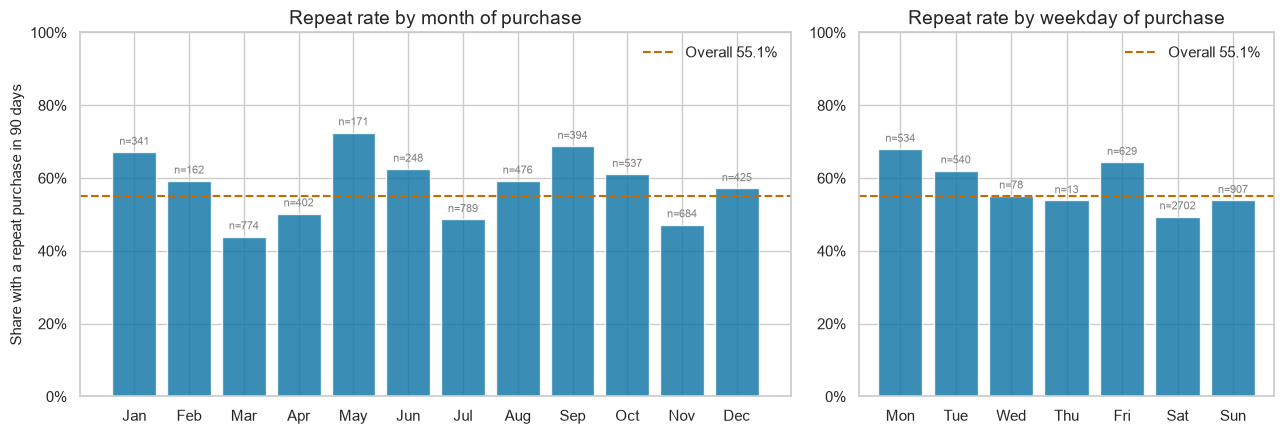

In [613]:
# Repeat rate and number of purchases by month and by weekday
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [12, 7]})
overall = dev_cal[target].mean()

for ax, col, labels in [
    (axes[0], "month", ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]),
    (axes[1], "day_of_week", ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]),
]:
    stats_by = dev_cal.groupby(col)[target].agg(["mean", "size"]).reindex(range(dev_cal[col].min(), dev_cal[col].max() + 1))
    x = np.arange(len(stats_by))
    ax.bar(x, stats_by["mean"], color="#1779A8", alpha=0.85)
    ax.axhline(overall, color="#C96A00", ls="--", lw=1.5, label=f"Overall {overall:.1%}")
    ax.set_xticks(x)
    ax.set_xticklabels(labels[: len(stats_by)] if col == "month" else [labels[i] for i in stats_by.index])
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    for xi, (rate, n) in enumerate(zip(stats_by["mean"], stats_by["size"])):
        if pd.notna(rate):
            ax.text(xi, rate + 0.02, f"n={int(n)}", ha="center", fontsize=8, color="grey")
    ax.legend(frameon=False, loc="upper right")

axes[0].set_title("Repeat rate by month of purchase")
axes[1].set_title("Repeat rate by weekday of purchase")
axes[0].set_ylabel("Share with a repeat purchase in 90 days")
plt.tight_layout()
plt.show()

In [614]:
CAL_LINEAR = {
    "F": ["month_sin", "month_cos"],
    "G": ["dow_sin", "dow_cos"],
}

CAL_TREE = {
    "F": ["month"],
    "G": ["day_of_week"],
}

# Linear branch: use only the engineered features retained so far.
options_62_linear = {
    "base": {
        "data": dev_cal,
        "extra_num": LINEAR_EXTRA,
    },
}

for group, cols in CAL_LINEAR.items():
    options_62_linear[f"group_{group}"] = {
        "data": dev_cal,
        "extra_num": LINEAR_EXTRA + cols,
    }

# Tree branch: use only the engineered features retained so far.
options_62_tree = {
    "base": {
        "data": dev_cal,
        "extra_num": TREE_EXTRA,
    },
}

for group, cols in CAL_TREE.items():
    options_62_tree[f"group_{group}"] = {
        "data": dev_cal,
        "extra_num": TREE_EXTRA + cols,
    }

table_62_lin, runs_62_lin = compare_options(
    "logistic",
    options_62_linear,
    "base",
    folds,
)

print("logistic")
display(table_62_lin)

table_62_tree, runs_62_tree = compare_options(
    "hist_gb",
    options_62_tree,
    "base",
    folds,
)

print("\nhist_gb")
display(table_62_tree)

logistic


,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
base,70.250,0.737,0.000,NaN,NaN,0,0.320,0.575,0.114,0.775,reference
group_F,72.250,0.734,-0.003,-0.012,0.006,3,0.300,0.579,0.110,0.771,no clear difference
group_G,72.250,0.737,0.001,-0.003,0.004,2,0.320,0.575,0.114,0.775,no clear difference



hist_gb


,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
base,42.000,0.739,0.000,NaN,NaN,0,0.260,0.606,0.083,0.764,reference
group_F,43.000,0.735,-0.004,-0.018,0.008,3,0.300,0.605,0.084,0.769,no clear difference
group_G,43.000,0.731,-0.008,-0.020,0.002,4,0.320,0.606,0.083,0.764,no clear difference


Month and weekday features are not retained. Neither passes the exploratory F1 improvement rule for either model, and all comparison intervals include zero.

For logistic regression, month reduces stacked F1 from approximately 0.737 to 0.734, while weekday produces little change. For histogram gradient boosting, month gives F1 of 0.735 and weekday gives 0.731, compared with 0.739 for the reference.

Differences in the descriptive month and weekday charts do not establish that these features add predictive value beyond the existing inputs. Customer composition and other factors may contribute, but these experiments do not identify the cause.

Because the dates are anonymised, the observed calendar patterns do not establish real business seasonality, ordering routines or batch-posting behaviour.

In [615]:
log.record(
    "D25",
    "month, day_of_week",
    "exclude month and weekday features",
    (
        "Neither calendar feature passed the exploratory F1 "
        "improvement rule for either model; all comparison "
        "intervals included zero. Anonymised calendar labels "
        "do not establish real business seasonality or routines."
    ),
    0,
    0,
    carries={
        "calendar": False,
        "year_excluded": (
            "Not tested as a predictor here; later test dates "
            "raise concerns about generalisation over time."
        ),
    },
)

display(log.to_frame().tail(1))

,step,column,action,reason,rows_train,rows_test
26,D25,"month, day_of_week",exclude month and weekday features,Neither calendar feature passed the exploratory F1 improvement rule for either model; all compar...,0,0


**Customer start year.** Section 2.5 identified 41 test observations whose recorded customer start year is later than any observed in the labelled training data. Chronological validation can expose similar changes in the range of this feature.

Three configurations are compared using both reference models:

- **since_year:** retain customer_since_year. This is the reference.
- **years_as_customer:** replace it with purchase year minus customer start year.
- **drop:** exclude customer_since_year without adding a replacement.

The relative feature describes approximate relationship duration in calendar years rather than the customer's start cohort. These representations are therefore not interchangeable and may support different predictions.

The relative feature may reduce some differences between training and future values, but it does not guarantee that future observations remain within the training range.

The same exploratory decision rule used elsewhere is applied here. If no alternative passes, the reference is retained.

In [616]:
SINCE = "customer_since_year"

# Inspect ranges without learning preprocessing parameters from test.
test_years = (
    test_clean["purchase_date"].dt.year
    - test_clean[SINCE]
)

print(
    f"customer_since_year  dev: "
    f"{dev_cal[SINCE].min()} to {dev_cal[SINCE].max()} | "
    f"test: {test_clean[SINCE].min()} to {test_clean[SINCE].max()}"
)

print(
    f"years_as_customer    dev: "
    f"{dev_cal['years_as_customer'].min()} "
    f"to {dev_cal['years_as_customer'].max()} | "
    f"test: {test_years.min()} to {test_years.max()}"
)

num_relative = [
    col for col in num_features if col != SINCE
] + ["years_as_customer"]

num_without = [
    col for col in num_features if col != SINCE
]

options_since_lin = {
    "since_year": {
        "data": dev_cal,
        "extra_num": LINEAR_EXTRA,
    },
    "years_as_customer": {
        "data": dev_cal,
        "num": num_relative,
        "extra_num": LINEAR_EXTRA,
    },
    "drop": {
        "data": dev_cal,
        "num": num_without,
        "extra_num": LINEAR_EXTRA,
    },
}

options_since_tree = {
    "since_year": {
        "data": dev_cal,
        "extra_num": TREE_EXTRA,
    },
    "years_as_customer": {
        "data": dev_cal,
        "num": num_relative,
        "extra_num": TREE_EXTRA,
    },
    "drop": {
        "data": dev_cal,
        "num": num_without,
        "extra_num": TREE_EXTRA,
    },
}

table_since_lin, runs_since_lin = compare_options(
    "logistic", options_since_lin, "since_year", folds
)
print("\nlogistic")
display(table_since_lin)

table_since_tree, runs_since_tree = compare_options(
    "hist_gb", options_since_tree, "since_year", folds
)
print("\nhist_gb")
display(table_since_tree)

customer_since_year  dev: 2015 to 2023 | test: 2015 to 2026
years_as_customer    dev: 0 to 8 | test: 0 to 11

logistic


,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
since_year,70.250,0.737,0.000,NaN,NaN,0,0.320,0.575,0.114,0.775,reference
years_as_customer,70.250,0.738,0.001,-0.006,0.007,2,0.330,0.577,0.112,0.770,no clear difference
drop,69.250,0.737,0.001,-0.005,0.006,3,0.340,0.576,0.113,0.771,no clear difference



hist_gb


,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
since_year,42.000,0.739,0.000,NaN,NaN,0,0.260,0.606,0.083,0.764,reference
years_as_customer,42.000,0.729,-0.010,-0.021,0.001,4,0.250,0.610,0.079,0.760,no clear difference
drop,41.000,0.728,-0.011,-0.020,-0.001,3,0.240,0.614,0.075,0.755,worse


Neither replacing nor removing customer_since_year passes the improvement rule.

For logistic regression, the alternatives give similar F1 values, with comparison intervals containing zero. Both have slightly higher mean log-loss and lower ROC-AUC than the reference.

For histogram gradient boosting, replacing start year with approximate relationship duration lowers F1 from 0.739 to 0.729, although its interval includes zero. Dropping start year lowers F1 to 0.728, with the comparison interval entirely below zero.

The relative feature also extends beyond its development range: years_as_customer ranges from 0 to 8 in development and 0 to 11 in test. Replacing the year therefore does not eliminate values outside the development range.

A separate logistic regression experiment below tests clipping numeric inputs to each training fold's observed range. This changes all numeric columns, so its result cannot be attributed to customer_since_year alone.

In [617]:
# Learn numeric clipping limits from each training fold only.
range_guard_steps = [
    ("clip", Winsorizer(0.0, 1.0)),
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
]

options_guard = {
    "since_year": {
        "data": dev_cal,
        "extra_num": LINEAR_EXTRA,
    },
    "since_year_clipped": {
        "data": dev_cal,
        "extra_num": LINEAR_EXTRA,
        "num_steps": range_guard_steps,
    },
}

table_guard, runs_guard = compare_options(
    "logistic",
    options_guard,
    "since_year",
    folds,
)

display(table_guard)

,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
since_year,70.250,0.737,0.000,NaN,NaN,0,0.320,0.575,0.114,0.775,reference
since_year_clipped,70.250,0.737,0.000,-0.006,0.005,2,0.340,0.574,0.115,0.774,no clear difference


Clipping numeric inputs to each training fold's observed range gives approximately the same stacked F1 as the reference (0.737). Its comparison interval includes zero, so it does not pass the improvement rule. Mean log-loss is slightly lower, while ROC-AUC is slightly lower.

customer_since_year is retained in both branches without additional clipping. None of the tested alternatives improves F1 under the decision rule, and removing the feature reduces histogram gradient boosting performance with an interval entirely below zero.

Future values outside the training range remain a generalisation concern. These development comparisons support the current choice but do not establish how either representation will perform on every future cohort.

In [618]:
log.record(
    "D26",
    "customer_since_year",
    "retain original feature in both branches without clipping",
    (
        "Neither replacement by approximate relationship duration "
        "nor removal passed the improvement rule. Removal reduced "
        "histogram gradient boosting F1 with an interval below zero. "
        "Clipping all numeric inputs showed no clear F1 improvement "
        "for logistic regression."
    ),
    0,
    0,
    carries={
        "customer_since_year": "keep",
        "numeric_range_clipping": False,
        "tested": [
            "years_as_customer",
            "drop",
            "clip all numeric inputs to training range",
        ],
    },
)

display(log.to_frame().tail(1))

,step,column,action,reason,rows_train,rows_test
27,D26,customer_since_year,retain original feature in both branches without clipping,Neither replacement by approximate relationship duration nor removal passed the improvement rule...,0,0


## 6.3. The customer's past repeat rate

Earlier labelled purchases may provide an additional summary of customer history: the proportion followed by another purchase within 90 days. This feature could overlap with existing purchase-count and interval variables, so its incremental value is tested.

Two restrictions prevent the feature from using unavailable outcomes:

- **Closed outcome windows only:** an earlier purchase contributes only when it occurred more than 90 days before the current purchase.
- **Training labels only:** the feature is constructed separately within each fold. Training observations use their customer's earlier eligible training purchases. Validation observations use eligible training purchases only, never validation labels. Test observations can similarly use available labelled training history.

Two features are added: the historical repeat rate and the number of eligible labelled purchases supporting it. The rate remains missing when no eligible history is available; the supporting count is zero.

Coverage is inspected first, followed by a comparison against each reference model. A descriptive association with the target does not by itself establish additional predictive value.

In [619]:
PAST_KEYS = ["customer_id", "purchase_date"]

def build_history(customers, dates, labels):
    """Per customer: sorted purchase dates and the running count of repeats."""
    hist = pd.DataFrame({
        "customer_id": np.asarray(customers),
        "date": pd.to_datetime(np.asarray(dates)).to_numpy(dtype="datetime64[ns]"),
        "y": np.asarray(labels).astype(int),
    }).sort_values(["customer_id", "date"])
    return {
        c: (g["date"].to_numpy(), np.concatenate([[0], np.cumsum(g["y"].to_numpy())]))
        for c, g in hist.groupby("customer_id")
    }

def past_counts(history, customers, dates):
    """For each row: earlier purchases with a closed 90-day window, and how many were repeats."""
    cutoff = (pd.to_datetime(np.asarray(dates)) - pd.Timedelta(days=GAP_DAYS)).to_numpy(dtype="datetime64[ns]")
    count = np.zeros(len(cutoff))
    repeats = np.zeros(len(cutoff))
    for i, (c, t) in enumerate(zip(np.asarray(customers), cutoff)):
        if c in history:
            past_dates, cum = history[c]
            k = np.searchsorted(past_dates, t, side="left")  # purchases dated before the cutoff
            count[i], repeats[i] = k, cum[k]
    return count, repeats

class PastRepeatRate(BaseEstimator, TransformerMixin):
    """Remember the training labels; give each row the repeat rate of its customer's closed past purchases."""

    def fit(self, X, y):
        self.history_ = build_history(X["customer_id"], X["purchase_date"], y)
        return self

    def transform(self, X):
        count, repeats = past_counts(self.history_, X["customer_id"], X["purchase_date"])
        rate = np.where(count > 0, repeats / np.maximum(count, 1), np.nan)
        return pd.DataFrame({"past_repeat_rate": rate, "past_labelled_count": count}, index=X.index)

    def get_feature_names_out(self, input_features=None):
        return np.array(["past_repeat_rate", "past_labelled_count"])

In [620]:
# Coverage only, no model: how many rows have at least one earlier closed purchase?
dev_hist = build_history(dev_cal["customer_id"], dev_cal["purchase_date"], dev_cal[target])
dev_count, dev_rep = past_counts(dev_hist, dev_cal["customer_id"], dev_cal["purchase_date"])

# Test rows can only use training labels, all of which have closed windows by then
train_hist = build_history(train_clean["customer_id"], train_clean["purchase_date"], train_clean[target])
test_count, _ = past_counts(train_hist, test_clean["customer_id"], test_clean["purchase_date"])

print(f"Dev rows with at least one earlier closed purchase:  {(dev_count > 0).mean():.1%}")
print(f"Test rows with at least one earlier closed purchase: {(test_count > 0).mean():.1%}")
print(f"Median count when present, dev: {np.median(dev_count[dev_count > 0]):.0f} | "
      f"test: {np.median(test_count[test_count > 0]):.0f}")

# First look: repeat share now, by past repeat rate band (dev only, for reading, not deciding)
has = dev_count > 0
bands = pd.cut(dev_rep[has] / dev_count[has], bins=[-0.01, 0.25, 0.5, 0.75, 1.0],
               labels=["0-25%", "25-50%", "50-75%", "75-100%"])
display(dev_cal.loc[has, target].groupby(bands, observed=False).agg(["mean", "size"])
        .rename(columns={"mean": "repeat_share_now", "size": "rows"}))

Dev rows with at least one earlier closed purchase:  84.0%
Test rows with at least one earlier closed purchase: 94.5%
Median count when present, dev: 11 | test: 24


,repeat_share_now,rows
0-25%,0.287,1101
25-50%,0.433,906
50-75%,0.599,863
75-100%,0.833,1667


The coverage figures show how often earlier labelled purchases with closed outcome windows are available. The grouped table describes the association between historical repeat rate and the current target within development data.

This descriptive association does not establish additional predictive value beyond the existing history features. The model comparison below constructs the feature separately within each fold, using labels from that fold's training portion only.

The comparison adds the two columns to each reference model and checks them with the usual rule. For logistic regression the rate is filled with the training median when missing and then scaled. Gradient boosting reads the missing values as they are.

In [621]:
def with_past(pipe, model_name):
    """Add a past-repeat block to a copy of the reference pipeline."""
    pipe = clone(pipe)
    prep = pipe.named_steps["prep"]

    if model_name == "hist_gb":
        block = PastRepeatRate()
    else:
        block = Pipeline([
            ("past", PastRepeatRate()),
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ])

    prep.set_params(
        transformers=prep.transformers + [
            ("past", block, PAST_KEYS),
        ]
    )

    return pipe


# Use the features retained so far in each branch.
base_lin = make_reference_models(
    num_features + LINEAR_EXTRA,
    high_card,
    low_card,
)["logistic"]

base_tree = make_reference_models(
    num_features + TREE_EXTRA,
    high_card,
    low_card,
)["hist_gb"]

inputs_lin = (
    num_features + LINEAR_EXTRA
    + high_card + low_card + PAST_KEYS
)

inputs_tree = (
    num_features + TREE_EXTRA
    + high_card + low_card + PAST_KEYS
)

results_63 = {}

for model_name, base, inputs in [
    ("logistic", base_lin, inputs_lin),
    ("hist_gb", base_tree, inputs_tree),
]:
    runs = {
        "base": score_folds(
            base, dev_cal, folds, inputs
        ),
        "past_rate": score_folds(
            with_past(base, model_name),
            dev_cal,
            folds,
            inputs,
        ),
    }

    results_63[model_name] = judge(runs, "base")

    print(f"\n{model_name}")
    display(results_63[model_name])


logistic


,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
base,70.250,0.737,0.000,NaN,NaN,0,0.320,0.575,0.114,0.775,reference
past_rate,72.250,0.741,0.004,-0.004,0.012,2,0.350,0.568,0.120,0.776,no clear difference



hist_gb


,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
base,42.000,0.739,0.000,NaN,NaN,0,0.260,0.606,0.083,0.764,reference
past_rate,44.000,0.733,-0.006,-0.015,0.004,3,0.270,0.606,0.083,0.766,no clear difference


The past-repeat features are not adopted under the exploratory decision rule.

For logistic regression, stacked F1 increases from approximately 0.737 to 0.741, but the bootstrap interval for the difference includes zero and F1 is lower in two validation periods. Mean log-loss improves from 0.575 to 0.568.

For histogram gradient boosting, F1 decreases from 0.739 to 0.733, although its comparison interval also includes zero. Mean log-loss is approximately unchanged.

Overlap with existing history features and differences in the age of available labels may affect the feature's usefulness, but these comparisons do not establish the cause of the results.

The logistic regression log-loss improvement makes this a candidate for later probability-focused experiments. It does not provide sufficient evidence to adopt the feature under the current F1 rule.

In [622]:
log.record(
    "D27",
    "past_repeat_rate, past_labelled_count",
    "not added",
    (
        "Neither model passed the exploratory F1 improvement rule. "
        "Logistic regression F1 increased by approximately 0.004, "
        "but its interval included zero and two folds were worse. "
        "Its mean log-loss improved from 0.575 to 0.568. "
        "Histogram gradient boosting F1 decreased by approximately "
        "0.006, with an interval also containing zero."
    ),
    0,
    0,
    carries={
        "past_repeat_rate": False,
        "closed_window_days": GAP_DAYS,
        "labels_from": "training part only",
    },
)

display(log.to_frame().tail(1))

,step,column,action,reason,rows_train,rows_test
28,D27,"past_repeat_rate, past_labelled_count",not added,Neither model passed the exploratory F1 improvement rule. Logistic regression F1 increased by ap...,0,0


# 7. Feature selection and dimensionality reduction

This section tests whether reducing the inputs improves prediction or provides a simpler model without a clearly detected performance loss. Fewer features do not automatically guarantee better generalisation.

Both branches start from their reference inputs, without the engineered ratios, history markers or past-repeat features. customer_since_year is retained. random_noise remains available during these experiments so that the noise-probe method can use it as a reference.

The following approaches are compared:

- **Domain-based removal:** exclude city, postal_area and municipality, whose removal gave mixed results in section 5.5.
- **Noise probe:** retain original columns whose training-set permutation importance exceeds that of random_noise, then exclude random_noise. Because importance is measured on fitting data, this is an exploratory method with a risk of favouring overfitted features.
- **Filters:** variance filtering, mutual information, relevance with correlation filtering and Information Value.
- **Wrapper:** recursive feature elimination.
- **Embedded:** coefficient-based selection using lasso and elastic-net logistic regression.
- **Reduction:** PCA retaining 95% of the transformed input variance. This preserves variance, not necessarily predictive information.
- **Vote:** retain features selected by at least three of five specified selectors.

For the linear branch, selectors operate on the encoded matrix. The variance filter follows standardisation, so it mainly assesses constants and low-frequency indicator columns rather than differences in the original numeric variances.

For histogram gradient boosting, selection operates on original columns so that native categorical handling is preserved.

Selectors are fitted within each training fold. An option passing the improvement rule is preferred. When its comparison interval includes zero, fewer columns are preferred only if F1 is lower in no more than two validation periods. This is a preference for simplicity, not evidence of equivalent performance.

The selectors below learn which columns to keep from the training part of each fold. The model is then fitted on the kept columns and scored on the validation year.

In [623]:
def relevance(col, y):
    """Cramér's V for 0/1 columns, |point-biserial r| for everything else."""
    if np.nanstd(col) == 0:
        return 0.0
    if np.isin(col, [0.0, 1.0]).all():
        table = pd.crosstab(col, y)
        if min(table.shape) < 2:
            return 0.0
        chi2 = chi2_contingency(table, correction=False)[0]
        return float(np.sqrt(chi2 / table.to_numpy().sum()))
    r = pointbiserialr(y, col).statistic
    return 0.0 if np.isnan(r) else abs(r)

def information_value(x, y, bins=10, min_rows=20):
    """IV of one column: numbers in quantile bins, categories with rare levels grouped, missing as its own bin."""
    s = pd.Series(np.asarray(x) if not isinstance(x, pd.Series) else x.to_numpy())
    if pd.api.types.is_numeric_dtype(s) and s.nunique() > bins:
        groups = pd.qcut(s, q=bins, duplicates="drop").astype(str)
    else:
        groups = s.astype(str)
        counts = groups.value_counts()
        groups = groups.where(groups.map(counts) >= min_rows, "rare")
    tab = pd.crosstab(groups.to_numpy(), np.asarray(y).astype(int)).reindex(columns=[0, 1], fill_value=0)
    good = (tab[1] + 0.5) / (tab[1].sum() + 0.5 * len(tab))  # 0.5 avoids log(0)
    bad = (tab[0] + 0.5) / (tab[0].sum() + 0.5 * len(tab))
    return float(((good - bad) * np.log(good / bad)).sum())

class CorrelationFilter(SelectorMixin, BaseEstimator):
    """Rank by relevance, keep the top k, skipping columns too correlated with one already kept."""

    def __init__(self, k=20, redundancy=0.85):
        self.k = k
        self.redundancy = redundancy

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y).astype(int)
        rel = np.array([relevance(X[:, j], y) for j in range(X.shape[1])])
        with np.errstate(invalid="ignore", divide="ignore"):
            corr = np.nan_to_num(np.abs(np.corrcoef(X, rowvar=False)))
        keep = []
        for j in np.argsort(rel)[::-1]:
            if len(keep) == self.k:
                break
            if any(corr[j, i] > self.redundancy for i in keep):
                continue
            keep.append(j)
        self.mask_ = np.zeros(X.shape[1], dtype=bool)
        self.mask_[keep] = True
        return self

    def _get_support_mask(self):
        return self.mask_

class IVSelector(SelectorMixin, BaseEstimator):
    """Keep columns whose Information Value reaches the threshold."""

    def __init__(self, threshold=0.02):
        self.threshold = threshold

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        self.iv_ = np.array([information_value(X[:, j], y) for j in range(X.shape[1])])
        self.mask_ = self.iv_ >= self.threshold
        return self

    def _get_support_mask(self):
        return self.mask_

class VoteSelector(SelectorMixin, BaseEstimator):
    """Keep a column if at least `minimum` of the member selectors keep it."""

    def __init__(self, members=None, minimum=3):
        self.members = members
        self.minimum = minimum

    def fit(self, X, y):
        self.votes_ = sum(clone(sel).fit(X, y).get_support().astype(int) for _, sel in self.members)
        self.mask_ = self.votes_ >= self.minimum
        return self

    def _get_support_mask(self):
        return self.mask_

class ColumnSubsetModel(ClassifierMixin, BaseEstimator):
    """Pick original columns on the training rows, then fit a model built for those columns."""

    def __init__(self, builder=None, chooser=None):
        self.builder = builder
        self.chooser = chooser

    def fit(self, X, y):
        self.columns_ = list(self.chooser(X, y))
        self.model_ = self.builder(self.columns_).fit(X[self.columns_], y)
        self.classes_ = self.model_.classes_
        return self

    def predict_proba(self, X):
        return self.model_.predict_proba(X[self.columns_])

    def predict(self, X):
        return self.model_.predict(X[self.columns_])

Each option is evaluated as a complete pipeline on the same four chronological folds. The section 5 comparison rule is used, with the additional preference for fewer columns under the conditions stated above.

In [624]:
def compare_pipes(pipes, data, features, reference, folds, tie_rule=True):
    """Score ready-made pipelines on the folds and apply the decision rule."""
    runs = {name: score_folds(pipe, data, folds, features) for name, pipe in pipes.items()}
    return judge(runs, reference, tie_rule=tie_rule), runs

Options for both models are shown in the table below. The reference is the current setup, with no selection applied.

In [625]:
# Use only the engineered features retained in section 6.
lin_num = num_features + LINEAR_EXTRA
tree_num = num_features + TREE_EXTRA

lin_features = lin_num + high_card + low_card
tree_features = tree_num + high_card + low_card


def builder_for(model_name, num):
    """Build a reference pipeline for a subset of original columns."""
    def build(cols):
        return make_reference_models(
            [c for c in num if c in cols],
            [c for c in high_card if c in cols],
            [c for c in low_card if c in cols],
        )[model_name]

    return build


def domain_chooser(X, y):
    return [c for c in X.columns if c not in COARSE_DROP]


def probe_chooser_for(build):
    """Exploratory selection using training-set permutation importance."""
    def choose(X, y):
        full = build(list(X.columns)).fit(X, y)

        imp = permutation_importance(
            full,
            X,
            y,
            n_repeats=5,
            scoring="roc_auc",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )

        scores = pd.Series(
            imp.importances_mean,
            index=X.columns,
        )

        return [
            c
            for c in scores[scores > scores["random_noise"]].index
            if c != "random_noise"
        ]

    return choose


def iv_chooser(X, y):
    return [
        c for c in X.columns
        if information_value(X[c], y) >= 0.02
    ]


def linear_with(selector):
    """Reference preprocessing, selection, then logistic regression."""
    prep = make_reference_models(
        lin_num, high_card, low_card
    )["logistic"].named_steps["prep"]

    # Preserve numeric column positions even if a training column is empty.
    prep.set_params(num__impute__keep_empty_features=True)

    return Pipeline([
        ("prep", prep),
        ("select", selector),
        ("model", LogisticRegression(max_iter=5000)),
    ])


# Count variables are discrete even after standardisation.
DISCRETE_NUMERIC = {
    "N_ Detalhes",
    "invoice_count_current_purchase",
    "prior_purchase_count",
    "purchase_count_30d",
    "purchase_count_90d",
    "purchase_count_180d",
    "purchase_count_365d",
    "is_first_purchase",
    "is_single_purchase",
}


def mixed_mi(
    X,
    y,
    n_numeric,
    n_frequency,
    discrete_numeric_indices,
):
    """Mutual information with an explicit discrete-feature mask."""
    X = np.asarray(X, dtype=float).copy()

    # ColumnTransformer order: numeric, frequency, then one-hot.
    onehot_start = n_numeric + n_frequency

    if X.shape[1] < onehot_start:
        raise ValueError(
            "Encoded feature layout differs from the expected schema."
        )

    discrete = np.zeros(X.shape[1], dtype=bool)
    discrete[list(discrete_numeric_indices)] = True
    discrete[onehot_start:] = True

    # Encode discrete values as integer labels. This preserves their
    # information and avoids treating scaled counts as continuous labels.
    for j in np.flatnonzero(discrete):
        X[:, j] = np.unique(
            X[:, j], return_inverse=True
        )[1]

    return mutual_info_classif(
        X,
        y,
        discrete_features=discrete,
        random_state=RANDOM_STATE,
    )


mi = partial(
    mixed_mi,
    n_numeric=len(lin_num),
    n_frequency=len(high_card),
    discrete_numeric_indices=tuple(
        i for i, col in enumerate(lin_num)
        if col in DISCRETE_NUMERIC
    ),
)

lin_build = builder_for("logistic", lin_num)
tree_build = builder_for("hist_gb", tree_num)

l1 = LogisticRegression(
    l1_ratio=1,
    solver="liblinear",
    C=0.1,
    max_iter=5000,
    random_state=RANDOM_STATE,
)

enet = LogisticRegression(
    l1_ratio=0.5,
    solver="saga",
    C=0.1,
    max_iter=5000,
    random_state=RANDOM_STATE,
)

# Lasso: retain coefficients with absolute magnitude at least 1e-5.
LASSO_THRESHOLD = 1e-5

# Elastic net: retain coefficients at or above mean absolute magnitude.
# This is not the same as retaining every nonzero coefficient.
ENET_THRESHOLD = "mean"


pipes_lin = {
    "base": lin_build(lin_features),

    "domain": ColumnSubsetModel(
        lin_build, domain_chooser
    ),

    "noise_probe": ColumnSubsetModel(
        lin_build, probe_chooser_for(lin_build)
    ),

    "variance": linear_with(
        VarianceThreshold(threshold=0.01)
    ),

    "iv_0.02": linear_with(IVSelector(0.02)),

    **{
        f"mi_{k}": linear_with(SelectKBest(mi, k=k))
        for k in (10, 20, 30)
    },

    **{
        f"corr_{k}": linear_with(CorrelationFilter(k=k))
        for k in (10, 20, 30)
    },

    **{
        f"rfe_{k}": linear_with(
            RFE(
                LogisticRegression(max_iter=5000),
                n_features_to_select=k,
                step=5,
            )
        )
        for k in (10, 20, 30)
    },

    "lasso": linear_with(
        SelectFromModel(l1, threshold=LASSO_THRESHOLD)
    ),

    "elastic_net": linear_with(
        SelectFromModel(enet, threshold=ENET_THRESHOLD)
    ),

    "pca_95": linear_with(
        PCA(n_components=0.95, svd_solver="full")
    ),

    "vote_3of5": linear_with(
        VoteSelector(
            members=[
                ("mi", SelectKBest(mi, k=20)),
                ("corr", CorrelationFilter(k=20)),
                ("iv", IVSelector(0.02)),
                (
                    "rfe",
                    RFE(
                        LogisticRegression(max_iter=5000),
                        n_features_to_select=20,
                        step=5,
                    ),
                ),
                (
                    "lasso",
                    SelectFromModel(
                        l1,
                        threshold=LASSO_THRESHOLD,
                    ),
                ),
            ],
            minimum=3,
        )
    ),
}


pipes_tree = {
    "base": tree_build(tree_features),

    "domain": ColumnSubsetModel(
        tree_build, domain_chooser
    ),

    "noise_probe": ColumnSubsetModel(
        tree_build, probe_chooser_for(tree_build)
    ),

    "iv_0.02": ColumnSubsetModel(
        tree_build, iv_chooser
    ),
}

In [626]:
table_7_lin, runs_7_lin = compare_pipes(pipes_lin, dev_fe, lin_features, "base", folds)
print("logistic")
display(table_7_lin)

table_7_tree, runs_7_tree = compare_pipes(pipes_tree, dev_fe, tree_features, "base", folds)
print("\nhist_gb")
display(table_7_tree)

logistic


,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
base,70.250,0.737,0.000,NaN,NaN,0,0.320,0.575,0.114,0.775,reference
domain,67.250,0.739,0.002,-0.003,0.009,1,0.310,0.573,0.116,0.777,no clear difference; fewer columns preferred
noise_probe,59.500,0.739,0.002,-0.004,0.007,1,0.340,0.572,0.117,0.776,no clear difference; fewer columns preferred
variance,60.750,0.743,0.007,0.001,0.012,0,0.340,0.570,0.119,0.780,better
iv_0.02,36.750,0.745,0.008,-0.001,0.017,1,0.340,0.562,0.126,0.784,no clear difference; fewer columns preferred
mi_10,10.000,0.738,0.001,-0.012,0.013,2,0.410,0.565,0.124,0.774,no clear difference; fewer columns preferred
mi_20,20.000,0.738,0.001,-0.011,0.014,1,0.380,0.564,0.125,0.773,no clear difference; fewer columns preferred
mi_30,30.000,0.740,0.003,-0.008,0.013,2,0.380,0.568,0.121,0.778,no clear difference; fewer columns preferred
corr_10,10.000,0.738,0.002,-0.013,0.014,1,0.440,0.567,0.122,0.774,no clear difference; fewer columns preferred



hist_gb


,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
base,42.000,0.739,0.000,NaN,NaN,0,0.260,0.606,0.083,0.764,reference
domain,39.000,0.735,-0.003,-0.018,0.009,2,0.340,0.596,0.093,0.767,no clear difference; fewer columns preferred
noise_probe,3.250,0.723,-0.016,-0.033,0.000,3,0.360,0.613,0.076,0.721,no clear difference
iv_0.02,34.000,0.731,-0.007,-0.016,0.002,3,0.230,0.621,0.068,0.754,no clear difference


## 7.1. Domain knowledge

Removing city, postal_area and municipality gives no clearly detected F1 difference for either model. Both configurations satisfy the preference for fewer columns: their comparison intervals include zero, and F1 is lower in no more than two validation periods.

For logistic regression, removal increases stacked F1 from approximately 0.737 to 0.739 and reduces the encoded input count by three. This remains a candidate for the later comparison with elastic-net selection.

For histogram gradient boosting, removal lowers stacked F1 from approximately 0.739 to 0.735, while improving mean log-loss from 0.606 to 0.596. The smaller configuration is provisionally preferred under the simplicity rule; equivalent performance has not been established.

The tree comparison must be repeated after random_noise is removed, because the final input configuration differs from the one tested here.

In [627]:
log.record(
    "D28",
    ", ".join(COARSE_DROP),
    "provisionally prefer removal for the tree branch",
    (
        "For both models, the comparison interval included zero "
        "and removal satisfied the preference for fewer columns. "
        "The tree configuration improved mean log-loss but had "
        "lower stacked F1. Confirm the tree decision after removing "
        "random_noise; assess the linear candidate alongside "
        "elastic-net selection."
    ),
    0,
    0,
    carries={
        "tree_drop": COARSE_DROP,
        "provisional": True,
        "requires_recheck_without_noise": True,
    },
)

display(log.to_frame().tail(1))

,step,column,action,reason,rows_train,rows_test
29,D28,"city, postal_area, municipality",provisionally prefer removal for the tree branch,"For both models, the comparison interval included zero and removal satisfied the preference for ...",0,0


## 7.2. Noise probe

The noise-probe method uses training-set permutation importance to retain columns scoring above random_noise, then removes random_noise itself.

For logistic regression, the method gives stacked F1 of approximately 0.739 versus 0.737 for the reference. Its comparison interval includes zero and it satisfies the preference for fewer columns. However, other selection methods pass the improvement rule, while this probe does not.

For histogram gradient boosting, the probe retains approximately three columns on average and lowers F1 from 0.739 to 0.723. Its interval includes zero, but performance is lower in three folds, so it does not satisfy the simplicity rule.

The probe is not adopted. Measuring importance on the same observations used to fit the model can favour overfitted features, making random_noise an unreliable selection threshold in this experiment. These results do not establish that permutation importance on separate validation data would be ineffective.

The selection-frequency table below examines whether elastic net retains random_noise. Its name alone does not establish how the supplied variable was generated.

The next table records how often each encoded column is selected by elastic net across the four training folds.

Selection in all four folds indicates consistency across these particular training periods, rather than guaranteed importance in future data. One-hot categories can differ between folds, so a zero selection count may also reflect a column being unavailable in some folds.

In [628]:
keep_counts, all_names = {}, set()
for (tr, va), year in zip(folds, VAL_YEARS):
    train_part = dev_fe.iloc[tr]
    model = clone(pipes_lin["elastic_net"]).fit(train_part[lin_features], train_part[target])
    names = model.named_steps["prep"].get_feature_names_out()
    all_names.update(names)  # one-hot levels can differ slightly between folds
    for name in names[model.named_steps["select"].get_support()]:
        keep_counts[name] = keep_counts.get(name, 0) + 1

kept = pd.Series({n: keep_counts.get(n, 0) for n in all_names}, name="folds_kept")
status = pd.cut(kept, bins=[-1, 0, 3, 4], labels=["dropped", "unstable", "kept"])
kept_table = (
    pd.DataFrame({"folds_kept": kept, "status": status})
    .sort_values(["folds_kept"], ascending=False)
)

print(kept_table["status"].value_counts().to_dict())
display(kept_table)

{'dropped': 49, 'kept': 15, 'unstable': 10}


,folds_kept,status
num__prior_mean_purchase_value,4,kept
high__commercial_region_freq,4,kept
num__purchase_count_90d,4,kept
num__Total Imp_,4,kept
num__purchase_count_365d,4,kept
num__Total Liquido,4,kept
onehot__island_Island IS7: The Pivot Archipelago,4,kept
onehot__island_Island IS5: The Pivot Archipelago,4,kept
num__prior_purchase_count,4,kept
num__customer_tenure_days,4,kept


Elastic net selects 15 encoded features in all four folds, 10 in one to three folds and 49 in none.

Consistently selected features include net purchase value, tax, historical purchase counts, tenure, mean purchase value, annual spending, customer start year and several geographic encodings.

random_noise is never selected at the specified elastic-net settings. This supports excluding it from this linear configuration, without proving that it has no association under every possible model.

The history markers are not assessed in this table because they were excluded from the candidate inputs following section 6. Selection frequency is conditional on the available features, encoding and coefficient threshold; it is not a measure of causal importance.

In [629]:
log.record(
    "D29",
    "random_noise",
    "exclude from final candidate inputs",
    (
        "Elastic-net selection did not retain random_noise in any "
        "of the four folds at the specified settings. The training-set "
        "noise-probe method was not adopted. Evaluate the final "
        "noise-free tree configuration separately rather than "
        "assuming the linear result also establishes its tree effect."
    ),
    0,
    0,
    carries={
        "drop": ["random_noise"],
        "linear_selection_count": 0,
        "folds_assessed": len(folds),
        "tree_configuration_requires_recheck": True,
    },
)

display(log.to_frame().tail(1))

,step,column,action,reason,rows_train,rows_test
30,D29,random_noise,exclude from final candidate inputs,Elastic-net selection did not retain random_noise in any of the four folds at the specified sett...,0,0


## 7.3. Filter methods

Variance filtering passes the exploratory improvement rule: stacked F1 increases from approximately 0.737 to 0.743, its comparison interval is entirely above zero and no validation fold has lower F1. It retains approximately 61 encoded inputs on average.

Because this filter follows standardisation, it mainly removes constants and low-frequency one-hot indicators rather than numeric features with small original variances.

Information Value, mutual information and correlation filtering do not show clear F1 improvements. Several configurations satisfy the preference for fewer columns, while some also improve mean log-loss. These results support considering simpler configurations without establishing equivalent performance.

## 7.4. Wrapper and embedded methods

None of the recursive-elimination configurations passes the improvement rule. Keeping ten features gives the lowest observed F1 among these configurations, but its comparison interval includes zero.

Both lasso and elastic-net selection pass the improvement rule against the full reference. Lasso gives stacked F1 of approximately 0.748 with 31 selected inputs on average. Elastic net gives approximately 0.750 with 20 selected inputs. Both have positive comparison intervals and lower F1 in only one validation period.

Elastic net is taken forward because it combines the highest observed F1 with fewer selected inputs than lasso. These comparisons do not establish that elastic net is clearly better than lasso in a direct comparison.

The elastic-net selector retains coefficients at or above the mean absolute coefficient magnitude. It does not simply retain every nonzero coefficient.

## 7.5. Reduction and vote

PCA retaining 95% of input variance gives stacked F1 of approximately 0.745 with around 26 components. Its comparison interval includes zero, although it satisfies the preference for a smaller representation.

The voting selector gives F1 of approximately 0.739, with an interval containing zero and lower F1 in three validation periods. It does not satisfy the simplicity rule.

Neither approach is taken forward: elastic-net selection passes the improvement rule against the reference and retains named encoded features rather than replacing them with principal components.

## 7.6. Chaining a second selector before elastic net

Elastic-net selection is the current linear candidate. This experiment tests whether adding an earlier selection stage improves it:

- **Domain → elastic net:** remove city, postal_area and municipality before elastic-net selection.
- **Redundancy filter → elastic net:** remove features correlated above 0.85 with a more relevant retained feature, then apply elastic-net selection.
- **Recursive elimination → elastic net:** retain 30 features through recursive elimination, then apply elastic-net selection.

Each chain is compared with elastic net alone using the same folds and coefficient threshold.

Because a chain adds another processing step, it is adopted only if it passes the improvement rule. Otherwise, elastic net alone is retained. A comparison interval containing zero is treated as inconclusive, not as evidence of equivalent performance.

In [630]:
enet_select = SelectFromModel(
    enet,
    threshold=ENET_THRESHOLD,
)

def linear_chain(first_stage):
    """Linear preprocessing, a first selector, then elastic-net selection and logistic regression."""
    prep = make_reference_models(lin_num, high_card, low_card)["logistic"].named_steps["prep"]
    return Pipeline([
        ("prep", prep),
        ("filter", first_stage),
        ("select", clone(enet_select)),
        ("model", LogisticRegression(max_iter=5000)),
    ])

def enet_on(cols):
    """Elastic-net pipeline built for a subset of original columns (used after the domain drop)."""
    prep = make_reference_models(
        [c for c in lin_num if c in cols],
        [c for c in high_card if c in cols],
        [c for c in low_card if c in cols],
    )["logistic"].named_steps["prep"]
    return Pipeline([
        ("prep", prep),
        ("select", clone(enet_select)),
        ("model", LogisticRegression(max_iter=5000)),
    ])

pipes_chain = {
    "elastic_net": linear_with(clone(enet_select)),
    "domain_then_enet": ColumnSubsetModel(enet_on, domain_chooser),
    "redundancy_then_enet": linear_chain(CorrelationFilter(k=None, redundancy=0.85)),
    "rfe30_then_enet": linear_chain(RFE(LogisticRegression(max_iter=5000), n_features_to_select=30, step=5)),
}

# A chain adds a step, so it has to win clearly: no tie rule here
table_76, runs_76 = compare_pipes(pipes_chain, dev_fe, lin_features, "elastic_net", folds, tie_rule=False)
display(table_76)

,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
elastic_net,20.000,0.750,0.000,NaN,NaN,0,0.340,0.561,0.128,0.784,reference
domain_then_enet,17.750,0.751,0.000,-0.007,0.009,2,0.330,0.562,0.127,0.785,no clear difference
redundancy_then_enet,16.500,0.749,-0.001,-0.012,0.008,1,0.390,0.558,0.130,0.785,no clear difference
rfe30_then_enet,10.750,0.728,-0.023,-0.037,-0.011,4,0.390,0.569,0.120,0.776,worse


No chained selector passes the improvement rule against elastic net alone.

Removing fine geography first gives approximately the same stacked F1 (0.751 versus 0.750), with an interval containing zero and lower F1 in two validation periods. Redundancy filtering also gives an inconclusive difference.

Recursive elimination before elastic net reduces F1 to approximately 0.728. Its comparison interval is entirely below zero, and F1 is lower in all four validation periods.

Elastic net alone remains the linear candidate because the additional stages do not demonstrate an improvement under the rule specified for these experiments.

## 7.7. Sensitivity to elastic-net regularisation

The elastic-net selector has used C = 0.1. This experiment also tests C = 0.05 and C = 0.2 to assess sensitivity to regularisation strength. Smaller C means stronger regularisation.

Each configuration uses the same explicit coefficient threshold and is compared with the full reference model, without the preference for fewer columns.

Results across these three settings provide a limited sensitivity check. They do not establish general stability or identify an optimal C. Regularisation can be tuned further within development validation during modelling.

In [631]:
def enet_selector(C):
    """Elastic-net selection at a specified regularisation strength."""
    estimator = LogisticRegression(
        l1_ratio=0.5,
        solver="saga",
        C=C,
        max_iter=5000,
        random_state=RANDOM_STATE,
    )

    return SelectFromModel(
        estimator,
        threshold=ENET_THRESHOLD,
    )


pipes_stability = {
    "base": lin_build(lin_features),
    **{
        f"enet_C{C}": linear_with(enet_selector(C))
        for C in (0.05, 0.1, 0.2)
    },
}

table_77, runs_77 = compare_pipes(
    pipes_stability,
    dev_fe,
    lin_features,
    "base",
    folds,
    tie_rule=False,
)

display(table_77)

,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
base,70.250,0.737,0.000,NaN,NaN,0,0.320,0.575,0.114,0.775,reference
enet_C0.05,17.500,0.750,0.013,0.004,0.024,1,0.340,0.559,0.130,0.785,better
enet_C0.1,20.000,0.750,0.014,0.004,0.023,1,0.340,0.561,0.128,0.784,better
enet_C0.2,23.250,0.739,0.003,-0.007,0.011,1,0.360,0.564,0.124,0.780,no clear difference


Elastic-net selection passes the improvement rule at C = 0.05 and C = 0.1. Both give stacked F1 of approximately 0.750, with positive comparison intervals and lower F1 in only one validation period.

C = 0.05 retains approximately 18 inputs on average, compared with 20 at C = 0.1. It also has slightly lower mean log-loss and higher ROC-AUC. These results make it a competitive setting, but the comparisons against the full reference do not establish a clear difference between the two C values.

At C = 0.2, F1 is approximately 0.739 and the comparison interval includes zero. The observed benefit therefore depends on regularisation strength.

C = 0.1 remains the existing starting configuration for subsequent checks, rather than an established optimum. Both stronger settings should remain candidates for tuning within development validation.

In [632]:
log.record(
    "D30",
    "linear branch inputs",
    "elastic-net selection inside each fold; C = 0.1 starting configuration",
    (
        "Elastic net gave the highest observed F1 among the "
        "single-method configurations; lasso and variance filtering "
        "also passed the improvement rule against the full reference. "
        "No selector chain clearly improved elastic net alone. "
        "C = 0.05 and C = 0.1 passed the improvement rule; "
        "C = 0.2 did not. Retain C = 0.1 as the existing starting "
        "configuration and tune regularisation during modelling."
    ),
    0,
    0,
    carries={
        "strategy": {
            "kind": "single",
            "selector": (
                "SelectFromModel("
                "estimator=LogisticRegression("
                "l1_ratio=0.5, solver='saga', C=0.1, "
                "max_iter=5000, random_state=42), "
                "threshold='mean')"
            ),
            "threshold": ENET_THRESHOLD,
            "C_tried": [0.05, 0.1, 0.2],
            "starting_C": 0.1,
        },
    },
)

display(log.to_frame().tail(1))

,step,column,action,reason,rows_train,rows_test
31,D30,linear branch inputs,elastic-net selection inside each fold; C = 0.1 starting configuration,Elastic net gave the highest observed F1 among the single-method configurations; lasso and varia...,0,0


# 8. Final preprocessing and outputs

This section checks the reusable cleaning functions against the notebook implementation and evaluates final candidate pipelines using the decisions established above.

The shared Python module remains unchanged. Corrected pipeline builders are defined locally in this notebook. Modelling notebooks must use those corrected definitions before applying the updated decisions.

The reserved holdout outcomes are excluded from the comparisons and model selection performed here.

## 8.1. Cleaning checks

The module's cleaning output is compared with the notebook implementation for matching rows, order and shared values.

Candidate history-marker columns may remain in the cleaned data, but they are excluded from the final model inputs. Repair flags are also excluded.

Prediction dates are checked before cleaning so that missing dates cannot silently remove test observations. Prediction IDs must be preserved, even when rows are sorted internally.

In [633]:
# Validate prediction dates before calling the unchanged module.
test_dates = pd.to_datetime(
    test["purchase_date"],
    format="%Y-%m-%d",
    errors="raise",
)

if test_dates.isna().any():
    raise ValueError(
        "Test contains missing purchase dates. "
        "Define a prediction-time fallback before cleaning; "
        "test observations must not be silently dropped."
    )

assert test["ID"].notna().all(), "Test contains missing IDs."
assert test["ID"].is_unique, "Test contains duplicate IDs."

# Reuse the module's existing cleaning rules.
train_final = rpp.clean_raw(train, clientes)
test_final = rpp.clean_raw(test, clientes)

# Compare shared columns, including row order and data types.
for name, module_df, notebook_df in [
    ("train", train_final, train_clean),
    ("test", test_final, test_clean),
]:
    shared = [
        col for col in module_df.columns
        if col in notebook_df.columns
    ]

    pd.testing.assert_frame_equal(
        module_df[shared],
        notebook_df[shared],
    )

    print(f"{name}: {len(shared)} shared columns match.")

# Verify complete prediction coverage after internal sorting.
assert len(test_final) == len(test), (
    "Cleaning changed the number of test observations."
)

assert test_final["ID"].is_unique, (
    "Cleaning produced duplicate test IDs."
)

assert set(test_final["ID"]) == set(test["ID"]), (
    "Cleaning changed the set of test IDs."
)

# Candidate markers can remain in the data without entering the models.
assert set(rpp.HISTORY_MARKERS) <= set(train_final.columns)

for df in (train_final, test_final):
    assert not any(
        col.startswith("flag_") for col in df.columns
    ), "Repair flags remain in the cleaned output."

print(f"Train: {train_final.shape} | Test: {test_final.shape}")
print("All test observations and IDs are preserved.")

train: 51 shared columns match.
test: 50 shared columns match.
Train: (6469, 53) | Test: (986, 52)
All test observations and IDs are preserved.


## 8.2. Checking the final candidate pipelines

Local builders implement the updated decisions without changing the shared module.

The linear pipeline excludes history markers and random_noise, then applies median imputation, standard scaling, categorical encoding and elastic-net selection with an explicit mean coefficient threshold.

The histogram-gradient-boosting pipeline excludes random_noise and retains native categorical and missing-value handling. Its builder is specific to this estimator.

Fine-geography removal is reassessed against retaining those fields in the noise-free tree configuration. The same improvement and simplicity rules are applied.

All comparisons use the existing development folds. No holdout predictions are evaluated here.

In [634]:
dev_final, _ = rpp.split_dev_holdout(train_final)
roles = rpp.column_roles(dev_final)

# Existing fold indices must refer to the same observations.
assert dev_final["ID"].equals(dev["ID"]), (
    "Final development rows differ from the original fold data."
)

# Confirm the intended schema, excluding noise and history markers.
assert roles["num"] == [
    col for col in num_features if col not in rpp.NOISE
]
assert roles["high"] == high_card
assert roles["low"] == low_card


def final_role_lists(roles, extra=(), drop=()):
    """Return fresh column lists for the requested configuration."""
    excluded = set(drop)

    num = [
        col for col in list(roles["num"]) + list(extra)
        if col not in excluded
    ]
    high = [
        col for col in roles["high"]
        if col not in excluded
    ]
    low = [
        col for col in roles["low"]
        if col not in excluded
    ]

    return num, high, low


def build_final_linear_pipeline(model, roles):
    """Local linear pipeline following the updated notebook decisions."""
    num, high, low = final_role_lists(
        roles,
        extra=LINEAR_EXTRA,
    )

    prep = make_reference_models(
        num, high, low
    )["logistic"].named_steps["prep"]

    prep.set_params(num__impute__keep_empty_features=True)

    return Pipeline([
        ("prep", prep),
        (
            "select",
            SelectFromModel(
                LogisticRegression(
                    l1_ratio=0.5,
                    solver="saga",
                    C=0.1,
                    max_iter=5000,
                    random_state=RANDOM_STATE,
                ),
                threshold=ENET_THRESHOLD,
            ),
        ),
        ("model", clone(model)),
    ])


def build_final_hist_pipeline(model, roles, drop=()):
    """Local builder specifically for HistGradientBoostingClassifier."""
    if not isinstance(model, HistGradientBoostingClassifier):
        raise TypeError(
            "This builder supports HistGradientBoostingClassifier only. "
            "Other estimators require appropriate preprocessing."
        )

    num, high, low = final_role_lists(
        roles,
        extra=TREE_EXTRA,
        drop=drop,
    )

    pipe = make_reference_models(
        num, high, low
    )["hist_gb"]

    fitted_model = clone(model)
    fitted_model.set_params(
        categorical_features=list(range(len(low)))
    )

    pipe.set_params(model=fitted_model)
    return pipe


# Reassess geography after excluding random_noise.
tree_num_final, tree_high_final, tree_low_final = final_role_lists(
    roles,
    extra=TREE_EXTRA,
)

tree_inputs_final = (
    tree_num_final + tree_high_final + tree_low_final
)

hist_model = HistGradientBoostingClassifier(
    random_state=RANDOM_STATE
)

tree_candidates = {
    "keep_geography": build_final_hist_pipeline(
        hist_model, roles
    ),
    "drop_geography": build_final_hist_pipeline(
        hist_model, roles, drop=COARSE_DROP
    ),
}

table_tree_final, runs_tree_final = compare_pipes(
    tree_candidates,
    dev_final,
    tree_inputs_final,
    "keep_geography",
    folds,
    tie_rule=True,
)

print("Noise-free tree comparison")
display(table_tree_final)

# Apply the previously specified decision rule.
drop_verdict = table_tree_final.loc[
    "drop_geography", "verdict"
]

prefer_drop = drop_verdict in {
    "better",
    "no clear difference; fewer columns preferred",
}

TREE_DROP_FINAL = list(COARSE_DROP) if prefer_drop else []
tree_choice = (
    "drop_geography" if prefer_drop else "keep_geography"
)

print(f"Selected tree configuration: {tree_choice}")


# Evaluate the final linear candidate.
linear_num_final, linear_high_final, linear_low_final = (
    final_role_lists(roles, extra=LINEAR_EXTRA)
)

linear_inputs_final = (
    linear_num_final + linear_high_final + linear_low_final
)

linear_candidate = build_final_linear_pipeline(
    LogisticRegression(max_iter=5000),
    roles,
)

linear_table, linear_oof, linear_threshold = score_folds(
    linear_candidate,
    dev_final,
    folds,
    linear_inputs_final,
)

# Reuse the selected tree run rather than fitting it again.
tree_table, tree_oof, tree_threshold = runs_tree_final[
    tree_choice
]

final_summary = pd.DataFrame({
    "linear (logistic)": {
        "n_features": linear_table["n_features"].mean(),
        "f1_stacked": f1_score(
            linear_oof["y"],
            linear_oof["p"] >= linear_threshold,
        ),
        "log_loss": linear_table["log_loss"].mean(),
        "roc_auc": linear_table["roc_auc"].mean(),
        "threshold": linear_threshold,
    },
    "tree (hist_gb)": {
        "n_features": tree_table["n_features"].mean(),
        "f1_stacked": f1_score(
            tree_oof["y"],
            tree_oof["p"] >= tree_threshold,
        ),
        "log_loss": tree_table["log_loss"].mean(),
        "roc_auc": tree_table["roc_auc"].mean(),
        "threshold": tree_threshold,
    },
}).T

print("\nFinal candidate development results")
display(final_summary)

log.record(
    "D28",
    ", ".join(COARSE_DROP),
    "remove fine geography from the final tree candidate",
    (
        "Rechecked after excluding random_noise. Removal increased "
        "observed F1 from approximately 0.730 to 0.736, but the "
        "comparison interval included zero. It satisfied the "
        "simplicity rule with three fewer inputs and one worse fold."
    ),
    0,
    0,
    carries={
        "tree_drop": TREE_DROP_FINAL,
        "provisional": False,
        "rechecked_without_noise": True,
    },
)

display(log.to_frame().tail(1))

Noise-free tree comparison


,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
keep_geography,41.000,0.730,0.000,NaN,NaN,0,0.260,0.613,0.076,0.758,reference
drop_geography,38.000,0.736,0.006,-0.005,0.016,1,0.300,0.607,0.082,0.760,no clear difference; fewer columns preferred


Selected tree configuration: drop_geography

Final candidate development results


,n_features,f1_stacked,log_loss,roc_auc,threshold
linear (logistic),20.000,0.750,0.561,0.784,0.340
tree (hist_gb),38.000,0.736,0.607,0.760,0.300


,step,column,action,reason,rows_train,rows_test
31,D28,"city, postal_area, municipality",remove fine geography from the final tree candidate,Rechecked after excluding random_noise. Removal increased observed F1 from approximately 0.730 t...,0,0


## 8.3. Saving the outputs

The cleaned training file retains every dated observation, including development, gap and holdout rows, so the modelling notebooks can reconstruct the chronological splits. The cleaned test file preserves every prediction observation and its ID.

The cleaned datasets, decision log, column roles and final preprocessing configuration are saved in data/preprocessed. Both Parquet files are reloaded and checked.

The configuration records the decisions but does not change the shared Python module. Modelling notebooks must use builders implementing these settings, including exclusion of history markers and the explicit elastic-net selection threshold.

Predictions must be aligned to sample_submission by ID rather than relying on the internally sorted test-row order.

In [635]:
# Document the final settings; this file does not modify module behaviour.
final_config = {
    "validation": {
        "gap_days": GAP_DAYS,
        "holdout_start": HOLDOUT_START.strftime("%Y-%m-%d"),
        "validation_years": VAL_YEARS,
    },
    "excluded_noise": list(rpp.NOISE),
    "linear": {
        "extra_features": list(LINEAR_EXTRA),
        "numeric_imputation": "median",
        "numeric_scaling": "standard",
        "high_card_encoding": "frequency",
        "low_card_encoding": "onehot",
        "rare_min_rows": RARE_MIN_ROWS,
        "selector": "elastic_net",
        "selector_C": 0.1,
        "selector_l1_ratio": 0.5,
        "selector_threshold": ENET_THRESHOLD,
    },
    "hist_gradient_boosting": {
        "extra_features": list(TREE_EXTRA),
        "drop_columns": list(TREE_DROP_FINAL),
        "numeric_imputation": None,
        "high_card_encoding": "frequency",
        "low_card_encoding": "native_categorical",
    },
    "implementation": (
        "Local notebook builders; shared module builders "
        "have not been updated."
    ),
}

train_final.to_parquet(
    PROCESSED_DIR / "train_clean.parquet",
    index=False,
)
test_final.to_parquet(
    PROCESSED_DIR / "test_clean.parquet",
    index=False,
)

log.to_json(PROCESSED_DIR / "decision_log.json")

(PROCESSED_DIR / "column_roles.json").write_text(
    json.dumps(roles, indent=2),
    encoding="utf-8",
)

(PROCESSED_DIR / "preprocessing_config.json").write_text(
    json.dumps(final_config, indent=2),
    encoding="utf-8",
)

# Check both saved datasets, including row order and data types.
check_train = pd.read_parquet(
    PROCESSED_DIR / "train_clean.parquet"
)
check_test = pd.read_parquet(
    PROCESSED_DIR / "test_clean.parquet"
)

pd.testing.assert_frame_equal(check_train, train_final)
pd.testing.assert_frame_equal(check_test, test_final)

# Verify that predictions can cover the submission IDs exactly.
assert sample_submission["ID"].notna().all()
assert sample_submission["ID"].is_unique
assert len(sample_submission) == len(check_test)
assert set(sample_submission["ID"]) == set(check_test["ID"])

# Check the saved configuration too.
saved_config = json.loads(
    (PROCESSED_DIR / "preprocessing_config.json").read_text(
        encoding="utf-8"
    )
)
assert saved_config == final_config

print("Both cleaned datasets and the configuration passed reload checks.")
print("Submission IDs match the cleaned test IDs.")

for filename in [
    "train_clean.parquet",
    "test_clean.parquet",
    "decision_log.json",
    "column_roles.json",
    "preprocessing_config.json",
]:
    file_path = PROCESSED_DIR / filename
    print(f"{filename:<30} {file_path.stat().st_size / 1024:,.1f} KiB")

Both cleaned datasets and the configuration passed reload checks.
Submission IDs match the cleaned test IDs.
train_clean.parquet            915.1 KiB
test_clean.parquet             182.1 KiB
decision_log.json              14.8 KiB
column_roles.json              1.0 KiB
preprocessing_config.json      0.9 KiB


The module's cleaning output matches the notebook implementation on all shared columns: 51 for training and 50 for test. All 986 test observations and their IDs are preserved.

Using the final candidate configurations, logistic regression gives development F1 of approximately 0.750 with 20 selected inputs on average. Histogram gradient boosting gives approximately 0.736 with 38 inputs after excluding random_noise and the three fine-geography fields.

These are development estimates, not reserved-holdout results.

Both cleaned datasets passed Parquet reload checks. The decision log, column roles and preprocessing configuration are saved alongside them in data/preprocessed.

The corrected pipeline builders remain local to this notebook. Modelling notebooks must implement the saved configuration rather than assuming the unchanged module builders already reproduce it.

# 9. Summary of decisions

| Area | Decision | Evidence or qualification |
|---|---|---|
| Customer join | Left join with many-to-one validation | Shared values match the notebook implementation; prediction rows and IDs are preserved. |
| Missing dates | Exclude 65 undated training observations | They cannot be assigned to chronological validation. Missing test dates raise an error before cleaning. |
| Placeholders | Replace identified interval and amount placeholders with missing values | Rules are applied consistently to training and test data. |
| Reconstruction | Reconstruct using the stated reliability assumptions | No assessed violations remain under the tested rules. Passing these checks does not prove accuracy. |
| Validation | Four expanding chronological folds with a 90-day outcome-window gap; holdout begins January 2024 | Assertions verify that training outcome windows end before validation begins. |
| Comparisons | Use F1, customer-bootstrap intervals and fold consistency | Development comparisons remain subject to threshold-selection and multiple-comparison uncertainty. |
| Threshold | Select a tested threshold within a continuous near-best range | Prevents selecting a poor threshold between disconnected ranges. |
| Invalid values | Retain reconstructed values without repair flags | No alternative passed the improvement rule. |
| Missing values | Median imputation for the linear branch; native handling for histogram gradient boosting | Tested alternatives did not clearly improve linear-model F1. |
| Outliers | No additional clipping or row filtering | Winsorising gave no clear F1 improvement; aggressive IQR filtering performed worse. |
| Scaling | Standard scaling for the linear branch | No tested alternative clearly improved F1. Log1p improved mean log-loss. |
| Categorical encoding | Frequency encoding for large categorical fields | Small fields use one-hot encoding for the linear branch and native categorical handling for histogram gradient boosting. |
| Customer attributes | Retain the reference customer attributes, subject to branch-specific selection | Removing them reduced histogram gradient boosting performance. |
| Engineered features | Do not add the tested ratios, history markers, calendar or past-repeat features | None passed the improvement rule in the updated comparisons. |
| Customer start year | Retain its original representation | Replacement, removal and range clipping did not improve F1 under the decision rule. |
| random_noise | Exclude from final candidate inputs | Elastic net never selected it; the final tree configuration was evaluated without it. |
| Linear selection | Elastic net with an explicit mean coefficient threshold | Highest observed single-method F1; lasso and variance filtering also improved on the full reference. |
| Regularisation | C = 0.1 remains a starting configuration | C = 0.05 also passed the improvement rule; C = 0.2 did not. Further tuning remains appropriate. |
| Tree selection | Remove city, postal_area and municipality | The noise-free comparison satisfied the preference for fewer inputs, without establishing equivalent performance. |
| Outputs | Save cleaned data, decisions, roles and configuration | Both datasets and the configuration passed reload checks; submission IDs match. |

## Implications for modelling

The final development comparisons favour the selected logistic-regression configuration over the tested histogram-gradient-boosting configuration on F1, log-loss and ROC-AUC. This does not establish the best model after broader model comparison and tuning.

The selected approach must still be evaluated on the reserved holdout after development choices are fixed.

## Next steps

- Make the modelling pipelines reproduce the saved preprocessing configuration. The shared module builders remain unchanged.
- Use estimator-appropriate preprocessing; the local tree builder supports HistGradientBoostingClassifier specifically.
- Tune models and selection parameters within chronological development validation.
- Derive classification thresholds from development predictions, without retuning on holdout outcomes.
- Report holdout performance separately for previously seen and unseen customers.
- Align submission predictions by ID.
- Treat calendar interpretations cautiously because dates are anonymised.